# GA Metode Koalisi — Open ATSP Jalan Daendels (Anyer → Panarukan)
**Tugas Teknik Optimalisasi.** Notebook ini: (1) mengambil matriks jarak **sepeda motor** (`TWO_WHEELER`) dari Google Maps Routes API, (2) mengoptimalkan urutan 52 titik dengan **Algoritma Genetika Metode Koalisi** (Bapak=Elit, Ibu=Pendatang Baru, Anak=crossover+mutasi+perbaikan, evaluasi fitness, elitisme), (3) membandingkan dengan Rute Referensi dan Nearest Neighbor, (4) membuat visualisasi dan ekspor.

**Catatan kejujuran metodologi:** jarak matriks = jarak rute *yang direkomendasikan* Google untuk sepeda motor (bukan jaminan jarak terpendek di antara semua jalan/gang); titik koordinat = titik pusat desa/kelurahan kecamatan (Google akan *snap* ke jalan terdekat); GA tidak menjamin optimum global.

## CELL 1 — Instalasi library
Colab sudah punya sebagian besar paket; sel ini memastikan `folium` dan `openpyxl` tersedia. Tidak perlu API Key.

In [ ]:
!pip -q install folium openpyxl seaborn requests pandas numpy matplotlib

## CELL 2 — Import library
Import semua paket dan set tampilan. Tidak perlu API Key.

In [ ]:
import os, sys, json, time, math, random, getpass, hashlib, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import folium
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 60)
try:
    from google.colab import files, drive, userdata
    IN_COLAB = True
except Exception:
    IN_COLAB = False
print("Colab:", IN_COLAB, "| Python", sys.version.split()[0], "| pandas", pd.__version__)

Colab: True | Python 3.13.16 | pandas 2.2.3


## CELL 3 — Konfigurasi program dan API Key
Semua parameter dapat diubah di `CONFIG`. **API Key tidak ditulis di kode**: dibaca dari environment variable / Colab Secret / `getpass` (dipanggil di Cell 6 hanya saat diperlukan).

In [ ]:
CONFIG = dict(
    # --- penyimpanan ---
    USE_DRIVE= True,                 # True => simpan di Google Drive (cache bertahan antar sesi)
    WORK_DIR="/content/daendels_ga",
    # --- API ---
    API_MODE="reuse",                # "reuse" | "first" | "refresh"  (lihat petunjuk di atas)
    MATRIX_BLOCK=25,                 # 25x25 = 625 elemen/request (batas maksimum Routes API)
    CONFIRM_BEFORE_API=True,         # minta konfirmasi sebelum panggilan API berbayar
    # --- GA (parameter awal dari soal) ---
    POP_SIZE=100, MAX_GENERATIONS=500, CROSSOVER_RATE=0.90, MUTATION_RATE=0.15,
    N_ELITE=5, ELITISM_RATE=0.05, NEWCOMER_RATE=0.10, PATIENCE=75,
    RANDOM_SEED=42, N_RUNS=10,
    # --- pengaturan tambahan GA ---
    CROSSOVER_METHOD="ox",           # "ox" | "slide" (tukar-segmen + repair ala slide) | "mixed"
    MUTATION_MODE="mixed",           # "swap" | "inversion" | "mixed"
    N_CHILDREN=100, LOCAL_SEARCH_PROB=0.5, LOCAL_SEARCH_TRIES=20,
    DIVERSITY_KEEP=0.2, HEURISTIC_RATIO=0.4, TRACE_GENERATIONS=3,
    MIN_POINTS=52,                   # 1 awal + minimal 50 perantara + 1 akhir
)
if CONFIG["USE_DRIVE"] and IN_COLAB:
    drive.mount("/content/drive")
    CONFIG["WORK_DIR"] = "/content/drive/MyDrive/daendels_ga"
WORK = CONFIG["WORK_DIR"]
os.makedirs(WORK, exist_ok=True)
P = lambda name: os.path.join(WORK, name)          # path helper
GA_PARAMS = dict(pop_size=CONFIG["POP_SIZE"], max_generations=CONFIG["MAX_GENERATIONS"],
                 crossover_rate=CONFIG["CROSSOVER_RATE"], mutation_rate=CONFIG["MUTATION_RATE"],
                 n_elite=CONFIG["N_ELITE"], newcomer_rate=CONFIG["NEWCOMER_RATE"], patience=CONFIG["PATIENCE"],
                 n_children=CONFIG["N_CHILDREN"], local_search_prob=CONFIG["LOCAL_SEARCH_PROB"],
                 local_search_tries=CONFIG["LOCAL_SEARCH_TRIES"], crossover_method=CONFIG["CROSSOVER_METHOD"],
                 mutation_mode=CONFIG["MUTATION_MODE"], diversity_keep=CONFIG["DIVERSITY_KEEP"],
                 heuristic_ratio=CONFIG["HEURISTIC_RATIO"], trace_generations=CONFIG["TRACE_GENERATIONS"])
assert abs(CONFIG["N_ELITE"] / CONFIG["POP_SIZE"] - CONFIG["ELITISM_RATE"]) < 1e-9, "N_ELITE harus = ELITISM_RATE x POP_SIZE"

_API_KEY = None
def get_api_key():
    """Urutan: env var -> Colab Secret -> getpass. Key tidak pernah dicetak/ditulis ke file."""
    global _API_KEY
    if _API_KEY:
        return _API_KEY
    k = os.environ.get("GOOGLE_MAPS_API_KEY")
    if not k and IN_COLAB:
        try:
            k = userdata.get("GOOGLE_MAPS_API_KEY")
        except Exception:
            k = None
    if not k:
        k = getpass.getpass("Masukkan Google Maps API Key (Routes API): ").strip()
    if not k:
        raise RuntimeError("API Key kosong. Tanpa key hanya API_MODE='reuse' yang dapat dipakai.")
    _API_KEY = k
    return k
print("Folder kerja:", WORK, "| API_MODE =", CONFIG["API_MODE"])

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/daendels_ga | API_MODE = reuse


## CELL 4 — Pengumpulan dan verifikasi 52 titik lokasi (1 awal + 50 perantara + 1 akhir)
**Koridor:** jalur *modern* Pantura/Daendels Anyer → Panarukan yang masih relevan untuk sepeda motor (bukan jalur historis persis; jalur historis dapat melewati Bogor–Bandung–Sumedang, sedangkan data ini mengikuti koridor pantai utara). Urutan ID = urutan geografis Barat→Timur (dipakai sebagai **Rute Referensi**).

**Sumber & verifikasi (sudah dilakukan saat menyusun notebook ini):**
- **Nama + hierarki** (kecamatan ↔ kabupaten/kota ↔ provinsi) dicocokkan dengan kode wilayah resmi Kepmendagri pada repo `cahyadsn/wilayah` (`db/wilayah.sql`) → 52/52 cocok.
- **Koordinat** diambil dari dataset wilayah Kemendagri/BIG pada paket npm `geografis` v1.3.2 (`data/json/data.json`): titik = desa/kelurahan pusat kecamatan bila namanya sama dengan kecamatan, selain itu desa terdekat ke titik tengah kecamatan. Tidak ada koordinat yang diketik manual.
- **Keterbatasan:** koordinat belum dicek satu per satu pada peta Google; Google akan *snap* ke jalan terdekat. Periksa tampilan peta (Cell 19). Nama populer "Anyer" bukan nama resmi kecamatan (resmi: *Anyar*). Jakarta diwakili satu titik (Gambir); Kota Surabaya/Semarang/Bekasi/Tegal dll. masing-masing satu titik.

In [ ]:
CITY_ROWS = [
{
"ID": 1,
"Nama Kota/Lokasi": "Anyer",
"Kabupaten/Kota": "Kabupaten Serang",
"Provinsi": "Banten",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.053822,
"Longitude": 105.917774,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.04.30.2001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Nama resmi kecamatan: Anyar; 'Anyer' adalah nama populer kawasan titik nol Jalan Daendels. Titik = desa Anyar."
},
{
"ID": 2,
"Nama Kota/Lokasi": "Cilegon",
"Kabupaten/Kota": "Kota Cilegon",
"Provinsi": "Banten",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.035321,
"Longitude": 106.039284,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.72.02.1002); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Ciwedus' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 3,
"Nama Kota/Lokasi": "Ciruas",
"Kabupaten/Kota": "Kabupaten Serang",
"Provinsi": "Banten",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.104364,
"Longitude": 106.230957,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.04.09.2001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Ciruas' (pusat kecamatan)"
},
{
"ID": 4,
"Nama Kota/Lokasi": "Serang",
"Kabupaten/Kota": "Kota Serang",
"Provinsi": "Banten",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.126323,
"Longitude": 106.149893,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.73.01.1001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Serang' (pusat kecamatan)"
},
{
"ID": 5,
"Nama Kota/Lokasi": "Balaraja",
"Kabupaten/Kota": "Kabupaten Tangerang",
"Provinsi": "Banten",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.188986,
"Longitude": 106.45704,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.03.01.1001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Balaraja' (pusat kecamatan)"
},
{
"ID": 6,
"Nama Kota/Lokasi": "Tangerang",
"Kabupaten/Kota": "Kota Tangerang",
"Provinsi": "Banten",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.181242,
"Longitude": 106.63731,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.71.01.1007); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Sukasari' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 7,
"Nama Kota/Lokasi": "Jakarta (Gambir)",
"Kabupaten/Kota": "Kota Administrasi Jakarta Pusat",
"Provinsi": "DKI Jakarta",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.176263,
"Longitude": 106.829324,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 31.71.01.1001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Satu titik mewakili DKI Jakarta. Titik: desa/kelurahan 'Gambir' (pusat kecamatan)"
},
{
"ID": 8,
"Nama Kota/Lokasi": "Bekasi",
"Kabupaten/Kota": "Kota Bekasi",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.237424,
"Longitude": 107.027597,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.75.01.1003); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Durenjaya' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 9,
"Nama Kota/Lokasi": "Cibitung",
"Kabupaten/Kota": "Kabupaten Bekasi",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.246118,
"Longitude": 107.103516,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.16.07.2002); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Wanajaya' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 10,
"Nama Kota/Lokasi": "Cikarang",
"Kabupaten/Kota": "Kabupaten Bekasi",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.339409,
"Longitude": 107.190875,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.16.20.2004); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Hegarmukti' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 11,
"Nama Kota/Lokasi": "Karawang",
"Kabupaten/Kota": "Kabupaten Karawang",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.289306,
"Longitude": 107.288886,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.15.01.1005); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Tanjungpura' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 12,
"Nama Kota/Lokasi": "Cikampek",
"Kabupaten/Kota": "Kabupaten Karawang",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.408995,
"Longitude": 107.453821,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.15.13.2006); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Cikampek Selatan' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 13,
"Nama Kota/Lokasi": "Pamanukan",
"Kabupaten/Kota": "Kabupaten Subang",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.285282,
"Longitude": 107.804315,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.13.11.2004); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Pamanukan' (pusat kecamatan)"
},
{
"ID": 14,
"Nama Kota/Lokasi": "Kandanghaur",
"Kabupaten/Kota": "Kabupaten Indramayu",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.344745,
"Longitude": 108.087274,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.12.21.2009); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Ilir' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 15,
"Nama Kota/Lokasi": "Indramayu",
"Kabupaten/Kota": "Kabupaten Indramayu",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.342424,
"Longitude": 108.329599,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.12.15.1003); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Karangmalang' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 16,
"Nama Kota/Lokasi": "Jatibarang",
"Kabupaten/Kota": "Kabupaten Indramayu",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.467574,
"Longitude": 108.302169,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.12.13.2006); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Jatibarang' (pusat kecamatan)"
},
{
"ID": 17,
"Nama Kota/Lokasi": "Cirebon",
"Kabupaten/Kota": "Kota Cirebon",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.712843,
"Longitude": 108.558503,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.74.01.1001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kejaksan' (pusat kecamatan)"
},
{
"ID": 18,
"Nama Kota/Lokasi": "Losari",
"Kabupaten/Kota": "Kabupaten Cirebon",
"Provinsi": "Jawa Barat",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.814806,
"Longitude": 108.792846,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.09.03.2009); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Ambulu' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 19,
"Nama Kota/Lokasi": "Bulakamba",
"Kabupaten/Kota": "Kabupaten Brebes",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.864176,
"Longitude": 108.947385,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.29.14.2003); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Bulakamba' (pusat kecamatan)"
},
{
"ID": 20,
"Nama Kota/Lokasi": "Brebes",
"Kabupaten/Kota": "Kabupaten Brebes",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.875043,
"Longitude": 109.04174,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.29.09.1002); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Brebes' (pusat kecamatan)"
},
{
"ID": 21,
"Nama Kota/Lokasi": "Tegal",
"Kabupaten/Kota": "Kota Tegal",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.870762,
"Longitude": 109.138233,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.76.02.1004); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Mangkukusuman' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 22,
"Nama Kota/Lokasi": "Kramat",
"Kabupaten/Kota": "Kabupaten Tegal",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.872051,
"Longitude": 109.20773,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.28.15.2013); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kramat' (pusat kecamatan)"
},
{
"ID": 23,
"Nama Kota/Lokasi": "Pemalang",
"Kabupaten/Kota": "Kabupaten Pemalang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.912911,
"Longitude": 109.382446,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.27.08.1014); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Bojongbata' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 24,
"Nama Kota/Lokasi": "Comal",
"Kabupaten/Kota": "Kabupaten Pemalang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.882116,
"Longitude": 109.539119,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.27.12.2010); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Gedeg' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 25,
"Nama Kota/Lokasi": "Pekalongan",
"Kabupaten/Kota": "Kota Pekalongan",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.898763,
"Longitude": 109.666056,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.75.01.1003); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Podosugih' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 26,
"Nama Kota/Lokasi": "Batang",
"Kabupaten/Kota": "Kabupaten Batang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.911197,
"Longitude": 109.734965,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.25.11.1014); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Proyonanggan Tengah' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 27,
"Nama Kota/Lokasi": "Gringsing",
"Kabupaten/Kota": "Kabupaten Batang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.964201,
"Longitude": 110.04242,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.25.07.2010); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Gringsing' (pusat kecamatan)"
},
{
"ID": 28,
"Nama Kota/Lokasi": "Weleri",
"Kabupaten/Kota": "Kabupaten Kendal",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.967747,
"Longitude": 110.077876,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.24.12.2007); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Weleri' (pusat kecamatan)"
},
{
"ID": 29,
"Nama Kota/Lokasi": "Kendal",
"Kabupaten/Kota": "Kabupaten Kendal",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.92281,
"Longitude": 110.201611,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.24.15.1015); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Pegulon' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 30,
"Nama Kota/Lokasi": "Semarang",
"Kabupaten/Kota": "Kota Semarang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -6.979451,
"Longitude": 110.419099,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.74.01.1006); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kembangsari' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 31,
"Nama Kota/Lokasi": "Sayung",
"Kabupaten/Kota": "Kabupaten Demak",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.950141,
"Longitude": 110.512458,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.21.04.2010); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Sayung' (pusat kecamatan)"
},
{
"ID": 32,
"Nama Kota/Lokasi": "Demak",
"Kabupaten/Kota": "Kabupaten Demak",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.873469,
"Longitude": 110.645003,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.21.11.1017); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Betokan' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 33,
"Nama Kota/Lokasi": "Kudus",
"Kabupaten/Kota": "Kabupaten Kudus",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.805728,
"Longitude": 110.839632,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.19.02.2013); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Demaan' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 34,
"Nama Kota/Lokasi": "Pati",
"Kabupaten/Kota": "Kabupaten Pati",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.740603,
"Longitude": 111.048959,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.18.10.2022); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kutoharjo' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 35,
"Nama Kota/Lokasi": "Juwana",
"Kabupaten/Kota": "Kabupaten Pati",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.714427,
"Longitude": 111.146365,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.18.08.2024); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Pajeksan' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 36,
"Nama Kota/Lokasi": "Rembang",
"Kabupaten/Kota": "Kabupaten Rembang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.719738,
"Longitude": 111.359731,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.17.10.2033); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kabongankidul' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 37,
"Nama Kota/Lokasi": "Lasem",
"Kabupaten/Kota": "Kabupaten Rembang",
"Provinsi": "Jawa Tengah",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.690794,
"Longitude": 111.456161,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 33.17.14.2010); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Ngemplak' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 38,
"Nama Kota/Lokasi": "Tuban",
"Kabupaten/Kota": "Kabupaten Tuban",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -6.89524,
"Longitude": 112.052442,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.23.16.1009); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Ronggomulyo' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 39,
"Nama Kota/Lokasi": "Babat",
"Kabupaten/Kota": "Kabupaten Lamongan",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.098877,
"Longitude": 112.167104,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.24.05.1003); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Babat' (pusat kecamatan)"
},
{
"ID": 40,
"Nama Kota/Lokasi": "Lamongan",
"Kabupaten/Kota": "Kabupaten Lamongan",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.121782,
"Longitude": 112.402942,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.24.22.1013); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Sukomulyo' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 41,
"Nama Kota/Lokasi": "Gresik",
"Kabupaten/Kota": "Kabupaten Gresik",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.156963,
"Longitude": 112.654101,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.25.16.1017); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Pekauman' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 42,
"Nama Kota/Lokasi": "Surabaya",
"Kabupaten/Kota": "Kota Surabaya",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -7.257257,
"Longitude": 112.739461,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.78.07.1002); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Genteng' (pusat kecamatan)"
},
{
"ID": 43,
"Nama Kota/Lokasi": "Sidoarjo",
"Kabupaten/Kota": "Kabupaten Sidoarjo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.450886,
"Longitude": 112.715699,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.15.08.1013); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Sidokumpul' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 44,
"Nama Kota/Lokasi": "Bangil",
"Kabupaten/Kota": "Kabupaten Pasuruan",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.593913,
"Longitude": 112.790293,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.14.14.1006); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kersikan' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 45,
"Nama Kota/Lokasi": "Pasuruan",
"Kabupaten/Kota": "Kota Pasuruan",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -7.650713,
"Longitude": 112.897726,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.75.02.1006); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Purworejo' (pusat kecamatan)"
},
{
"ID": 46,
"Nama Kota/Lokasi": "Probolinggo",
"Kabupaten/Kota": "Kota Probolinggo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kota)",
"Latitude": -7.731596,
"Longitude": 113.215971,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.74.03.1001); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Mayangan' (pusat kecamatan)"
},
{
"ID": 47,
"Nama Kota/Lokasi": "Kraksaan",
"Kabupaten/Kota": "Kabupaten Probolinggo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.760462,
"Longitude": 113.428577,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.13.14.1007); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kraksaan Wetan' (paling dekat ke titik tengah kecamatan)"
},
{
"ID": 48,
"Nama Kota/Lokasi": "Paiton",
"Kabupaten/Kota": "Kabupaten Probolinggo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.725601,
"Longitude": 113.516464,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.13.12.2015); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Paiton' (pusat kecamatan)"
},
{
"ID": 49,
"Nama Kota/Lokasi": "Besuki",
"Kabupaten/Kota": "Kabupaten Situbondo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.733958,
"Longitude": 113.692725,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.12.02.2009); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Besuki' (pusat kecamatan)"
},
{
"ID": 50,
"Nama Kota/Lokasi": "Suboh",
"Kabupaten/Kota": "Kabupaten Situbondo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.743293,
"Longitude": 113.73628,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.12.03.2005); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Suboh' (pusat kecamatan)"
},
{
"ID": 51,
"Nama Kota/Lokasi": "Kendit",
"Kabupaten/Kota": "Kabupaten Situbondo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.734804,
"Longitude": 113.934606,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.12.05.2002); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Kendit' (pusat kecamatan)"
},
{
"ID": 52,
"Nama Kota/Lokasi": "Panarukan",
"Kabupaten/Kota": "Kabupaten Situbondo",
"Provinsi": "Jawa Timur",
"Jenis Wilayah": "Kecamatan (Kabupaten)",
"Latitude": -7.69897,
"Longitude": 113.964894,
"Sumber": "Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 35.12.06.2003); nama dicek vs cahyadsn/wilayah (Kepmendagri)",
"Nama_Terverifikasi": "YA",
"Catatan": "Titik: desa/kelurahan 'Wringinanom' (paling dekat ke titik tengah kecamatan)"
}
]

def validate_city_data(df, min_points=CONFIG["MIN_POINTS"]):
    """Validasi dataset: jumlah minimal, ID/nama unik, koordinat di Pulau Jawa, nama terverifikasi, start/end benar."""
    errs = []
    if len(df) < min_points: errs.append(f"Jumlah titik {len(df)} < {min_points}")
    if df["ID"].duplicated().any(): errs.append("ID duplikat")
    if df["Nama Kota/Lokasi"].duplicated().any(): errs.append("Nama lokasi duplikat")
    if df[["Latitude", "Longitude"]].isna().any().any(): errs.append("Koordinat kosong")
    if df.duplicated(["Latitude", "Longitude"]).any(): errs.append("Koordinat kembar (kota yang sama dihitung dua kali?)")
    if not df["Latitude"].between(-8.9, -5.8).all() or not df["Longitude"].between(105.0, 115.0).all():
        errs.append("Ada koordinat di luar kotak batas Pulau Jawa")
    if not (df["Nama_Terverifikasi"] == "YA").all(): errs.append("Ada nama yang belum terverifikasi")
    if df["Nama Kota/Lokasi"].iloc[0] != "Anyer": errs.append("Titik awal bukan Anyer")
    if df["Nama Kota/Lokasi"].iloc[-1] != "Panarukan": errs.append("Titik akhir bukan Panarukan")
    if not df["Longitude"].is_monotonic_increasing:
        errs.append("(peringatan) Longitude tidak naik monoton: urutan referensi tidak murni Barat->Timur")
    return errs

df_cities = pd.DataFrame(CITY_ROWS)
display(df_cities.drop(columns=["Catatan"]))
print("Jumlah titik:", len(df_cities), "| perantara:", len(df_cities) - 2)
print("Validasi:", validate_city_data(df_cities) or "OK")

,ID,Nama Kota/Lokasi,Kabupaten/Kota,Provinsi,Jenis Wilayah,Latitude,Longitude,Sumber,Nama_Terverifikasi
0,1,Anyer,Kabupaten Serang,Banten,Kecamatan (Kabupaten),-6.053822,105.917774,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.04.30...,YA
1,2,Cilegon,Kota Cilegon,Banten,Kecamatan (Kota),-6.035321,106.039284,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.72.02...,YA
2,3,Ciruas,Kabupaten Serang,Banten,Kecamatan (Kabupaten),-6.104364,106.230957,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.04.09...,YA
3,4,Serang,Kota Serang,Banten,Kecamatan (Kota),-6.126323,106.149893,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.73.01...,YA
4,5,Balaraja,Kabupaten Tangerang,Banten,Kecamatan (Kabupaten),-6.188986,106.457040,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.03.01...,YA
5,6,Tangerang,Kota Tangerang,Banten,Kecamatan (Kota),-6.181242,106.637310,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 36.71.01...,YA
6,7,Jakarta (Gambir),Kota Administrasi Jakarta Pusat,DKI Jakarta,Kecamatan (Kota),-6.176263,106.829324,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 31.71.01...,YA
7,8,Bekasi,Kota Bekasi,Jawa Barat,Kecamatan (Kota),-6.237424,107.027597,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.75.01...,YA
8,9,Cibitung,Kabupaten Bekasi,Jawa Barat,Kecamatan (Kabupaten),-6.246118,107.103516,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.16.07...,YA
9,10,Cikarang,Kabupaten Bekasi,Jawa Barat,Kecamatan (Kabupaten),-6.339409,107.190875,Kemendagri/BIG via npm 'geografis' v1.3.2 (kode 32.16.20...,YA


Jumlah titik: 52 | perantara: 50
Validasi: ['(peringatan) Longitude tidak naik monoton: urutan referensi tidak murni Barat->Timur']


## CELL 5 — Membentuk dan menyimpan dataset `cities.csv`
Menyimpan ke folder kerja lalu memuat kembali (`load_city_data`) agar seluruh notebook memakai berkas yang sama. Tidak perlu API Key.

In [ ]:
def save_city_data(df, path=P("cities.csv")):
    df.to_csv(path, index=False, encoding="utf-8-sig")
    return path

def load_city_data(path=P("cities.csv")):
    df = pd.read_csv(path, encoding="utf-8-sig")
    errs = [e for e in validate_city_data(df) if not e.startswith("(peringatan)")]
    if errs:
        raise ValueError("Dataset tidak valid: " + "; ".join(errs))
    return df.reset_index(drop=True)

save_city_data(df_cities)
cities = load_city_data()
N = len(cities); START, END = 0, N - 1
NAMES = cities["Nama Kota/Lokasi"].tolist()
print(f"cities.csv tersimpan di {P('cities.csv')} | N={N} | START={NAMES[START]} | END={NAMES[END]}")

cities.csv tersimpan di /content/drive/MyDrive/daendels_ga/cities.csv | N=52 | START=Anyer | END=Panarukan


## CELL 6 — Integrasi Google Maps Routes API *(BAGIAN A — butuh API Key bila API_MODE ≠ "reuse")*
Mendefinisikan: `get_route_matrix()`, `batch_route_requests()`, `save_route_cache()`, `load_route_cache()`, `fetch_route_matrix()`, `get_motorcycle_route()`, `get_alternative_routes()`. Konfigurasi tetap: **`travelMode="TWO_WHEELER"`**, `routingPreference="TRAFFIC_UNAWARE"`, region Indonesia (`id`), satuan metrik. Tidak ada fallback Haversine. Sel ini hanya mendefinisikan fungsi (belum memanggil API).

In [ ]:
"""Fungsi Google Maps Routes API (TWO_WHEELER) untuk proyek TSP Anyer-Panarukan.
Dokumentasi: https://developers.google.com/maps/documentation/routes
"""

TRAVEL_MODE = "TWO_WHEELER"          # WAJIB sepeda motor (bukan DRIVE/BICYCLE/WALK)
ROUTING_PREFERENCE = "TRAFFIC_UNAWARE"
MATRIX_URL = "https://routes.googleapis.com/distanceMatrix/v2:computeRouteMatrix"
ROUTES_URL = "https://routes.googleapis.com/directions/v2:computeRoutes"
MAX_MATRIX_ELEMENTS = 625            # batas elemen per request (non-TRAFFIC_AWARE_OPTIMAL)
PERMANENT_CONDITIONS = {"ROUTE_NOT_FOUND"}


class RoutesAPIError(Exception):
    pass


class APIKeyError(RoutesAPIError):
    pass

def _post_with_retry(url, body, fieldmask, api_key, max_retries=5, timeout=180):
    """POST ke Routes API dengan retry (429/5xx) dan pesan error yang jelas."""
    headers = {"Content-Type": "application/json", "X-Goog-Api-Key": api_key,
               "X-Goog-FieldMask": fieldmask}
    last = None
    for attempt in range(max_retries):
        try:
            r = requests.post(url, headers=headers, json=body, timeout=timeout)
        except requests.RequestException as e:
            last = f"Kesalahan jaringan: {e}"
            time.sleep(min(60, 2 ** attempt + random.random()))
            continue
        if r.status_code == 200:
            return r.json()
        text = r.text[:600]
        if r.status_code in (401, 403) or "API_KEY_INVALID" in text or "API key not valid" in text:
            raise APIKeyError(
                f"HTTP {r.status_code}: API Key tidak valid / ditolak. Periksa: (1) Routes API sudah di-ENABLE, "
                f"(2) billing aktif, (3) pembatasan API Key mengizinkan Routes API, (4) key tidak salah salin.\n{text}")
        if r.status_code in (429, 500, 502, 503, 504):
            wait = float(r.headers.get("Retry-After", 0)) or min(60, 2 ** attempt + random.random())
            last = f"HTTP {r.status_code} (limit/server) - tunggu {wait:.1f}s lalu coba lagi"
            print("  ", last)
            time.sleep(wait)
            continue
        raise RoutesAPIError(f"HTTP {r.status_code}: {text}")
    raise RoutesAPIError(f"Gagal setelah {max_retries} percobaan. Terakhir: {last}")


def _waypoint(lat, lng):
    return {"waypoint": {"location": {"latLng": {"latitude": float(lat), "longitude": float(lng)}}}}


def _parse_duration(s):
    if s is None:
        return None
    return float(str(s).rstrip("s"))


def pair_key(o, d, mode=TRAVEL_MODE, pref=ROUTING_PREFERENCE):
    """Kunci cache berbasis koordinat, mode, dan preferensi (aman jika urutan dataset berubah)."""
    return f"{mode}|{pref}|{o[0]:.6f},{o[1]:.6f}|{d[0]:.6f},{d[1]:.6f}"


def save_route_cache(cache, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(cache, f, ensure_ascii=False)
    os.replace(tmp, path)


def load_route_cache(path):
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            c = json.load(f)
        c.setdefault("meta", {})
        c.setdefault("elements", {})
        return c
    return {"meta": {"travelMode": TRAVEL_MODE, "routingPreference": ROUTING_PREFERENCE,
                     "method": "routes.v2.computeRouteMatrix"}, "elements": {}}


def get_route_matrix(origins, destinations, api_key):
    """Satu request computeRouteMatrix. origins/destinations: list (lat, lng).
    Mengembalikan dict {(i, j): elemen} dengan indeks relatif terhadap list input."""
    n_el = len(origins) * len(destinations)
    if n_el > MAX_MATRIX_ELEMENTS:
        raise ValueError(f"{n_el} elemen melebihi batas {MAX_MATRIX_ELEMENTS}")
    body = {
        "origins": [_waypoint(*o) for o in origins],
        "destinations": [_waypoint(*d) for d in destinations],
        "travelMode": TRAVEL_MODE,
        "routingPreference": ROUTING_PREFERENCE,
        "languageCode": "id-ID", "regionCode": "id", "units": "METRIC",
    }
    fm = "originIndex,destinationIndex,status,condition,distanceMeters,duration"  # 'status' wajib
    data = _post_with_retry(MATRIX_URL, body, fm, api_key)
    if isinstance(data, dict):
        data = data.get("elements", [data])
    out = {}
    for el in data:
        # JSON protobuf menghilangkan nilai default 0 -> gunakan .get(..., 0)
        i, j = int(el.get("originIndex", 0)), int(el.get("destinationIndex", 0))
        status = el.get("status") or {}
        cond = el.get("condition", "")
        ok = (not status.get("code")) and cond == "ROUTE_EXISTS"
        out[(i, j)] = {
            "ok": bool(ok), "condition": cond, "status": status,
            "d": float(el.get("distanceMeters", 0)) if ok else None,
            "t": _parse_duration(el.get("duration", "0s")) if ok else None,
        }
    return out


def batch_route_requests(n, block=25):
    """Bagi indeks 0..n-1 menjadi potongan seimbang <= block, hasil: list (rows, cols)."""
    if block * block > MAX_MATRIX_ELEMENTS:
        raise ValueError("block*block melebihi 625")
    k = int(math.ceil(n / block))
    chunks = [list(map(int, c)) for c in np.array_split(np.arange(n), k)]
    return [(r, c) for r in chunks for c in chunks]


def fetch_route_matrix(df, cache, api_key, mode="reuse", block=25, cache_path=None,
                       confirm=True, pause=0.3):
    """Isi cache matriks jarak. mode:
      'reuse'   : tidak memanggil API, hanya melaporkan yang belum ada di cache.
      'first'   : panggil API hanya untuk pasangan yang belum ada/gagal sementara (juga untuk melanjutkan).
      'refresh' : abaikan cache lama untuk pasangan ini, ambil ulang semuanya."""
    assert mode in ("reuse", "first", "refresh")
    coords = list(zip(df["Latitude"].astype(float), df["Longitude"].astype(float)))
    n = len(coords)
    els = cache["elements"]

    def needed(i, j):
        if i == j:
            return False
        e = els.get(pair_key(coords[i], coords[j]))
        if mode == "refresh":
            return True
        if e is None:
            return True
        return (not e["ok"]) and e.get("condition") not in PERMANENT_CONDITIONS

    blocks = batch_route_requests(n, block)
    todo = [(r, c) for (r, c) in blocks if any(needed(i, j) for i in r for j in c)]
    n_elements = sum(len(r) * len(c) for r, c in todo)
    n_missing = sum(needed(i, j) for i in range(n) for j in range(n))
    print(f"Titik: {n} | pasangan: {n*(n-1)} | perlu diambil/diperbarui: {n_missing} | "
          f"request: {len(todo)} | elemen yang ditagih: {n_elements}")
    if mode == "reuse" or not todo:
        print("Tidak ada panggilan API." if mode == "reuse" else "Cache sudah lengkap. Tidak ada panggilan API.")
        return {"requests": 0, "elements": 0, "missing": n_missing}
    if confirm:
        ans = input(f"Akan memanggil Routes API: {len(todo)} request / {n_elements} elemen (berbayar sesuai harga "
                    f"Google). Ketik YA untuk lanjut: ")
        if ans.strip().upper() != "YA":
            print("Dibatalkan oleh pengguna.")
            return {"requests": 0, "elements": 0, "missing": n_missing}
    api_key = api_key() if callable(api_key) else api_key   # key baru diminta saat benar-benar dipakai
    done = 0
    for bi, (r, c) in enumerate(todo, 1):
        res = get_route_matrix([coords[i] for i in r], [coords[j] for j in c], api_key)
        for a, i in enumerate(r):
            for b, j in enumerate(c):
                if i == j:
                    continue
                e = res.get((a, b))
                if e is None:
                    e = {"ok": False, "condition": "NO_RESPONSE", "status": {}, "d": None, "t": None}
                e["fetched_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
                els[pair_key(coords[i], coords[j])] = e
        done += len(r) * len(c)
        if cache_path:
            save_route_cache(cache, cache_path)   # simpan tiap batch -> aman jika sesi terputus
        print(f"  batch {bi}/{len(todo)} selesai ({len(r)}x{len(c)} elemen)")
        time.sleep(pause)
    return {"requests": len(todo), "elements": done, "missing": 0}


def build_matrices(df, cache):
    """Bentuk matriks BERARAH dari cache. Rute tidak tersedia -> inf (TIDAK diganti Haversine)."""
    coords = list(zip(df["Latitude"].astype(float), df["Longitude"].astype(float)))
    n = len(coords)
    D = np.full((n, n), np.inf)
    T = np.full((n, n), np.inf)
    rows = []
    for i in range(n):
        D[i, i] = 0.0
        T[i, i] = 0.0
        for j in range(n):
            if i == j:
                continue
            e = cache["elements"].get(pair_key(coords[i], coords[j]))
            if e is None:
                rows.append((i, j, "BELUM_DIAMBIL"))
            elif e["ok"]:
                D[i, j] = e["d"] / 1000.0
                T[i, j] = e["t"] / 60.0
            else:
                rows.append((i, j, e.get("condition") or json.dumps(e.get("status"))))
    status = pd.DataFrame(rows, columns=["i", "j", "status"])
    if len(status):
        status["Dari"] = df["Nama Kota/Lokasi"].values[status["i"]]
        status["Ke"] = df["Nama Kota/Lokasi"].values[status["j"]]
    return D, T, status

def decode_polyline(s):
    """Decoder Google encoded polyline -> list[(lat, lng)]."""
    pts, idx, lat, lng = [], 0, 0, 0
    while idx < len(s):
        for which in (0, 1):
            shift = result = 0
            while True:
                b = ord(s[idx]) - 63
                idx += 1
                result |= (b & 0x1F) << shift
                shift += 5
                if b < 0x20:
                    break
            delta = ~(result >> 1) if result & 1 else (result >> 1)
            if which == 0:
                lat += delta
            else:
                lng += delta
        pts.append((lat / 1e5, lng / 1e5))
    return pts


def get_motorcycle_route(origin, dest, api_key, alternatives=False):
    """Compute Routes untuk SATU pasangan (tanpa intermediate waypoint). origin/dest = (lat, lng).
    Mengembalikan list rute: {label, distance_km, duration_min, polyline, description}."""
    body = {
        "origin": {"location": {"latLng": {"latitude": float(origin[0]), "longitude": float(origin[1])}}},
        "destination": {"location": {"latLng": {"latitude": float(dest[0]), "longitude": float(dest[1])}}},
        "travelMode": TRAVEL_MODE, "routingPreference": ROUTING_PREFERENCE,
        "computeAlternativeRoutes": bool(alternatives),
        "languageCode": "id-ID", "regionCode": "id", "units": "METRIC",
    }
    fm = ("routes.distanceMeters,routes.duration,routes.routeLabels,"
          "routes.polyline.encodedPolyline,routes.description")
    data = _post_with_retry(ROUTES_URL, body, fm, api_key)
    out = []
    for r in data.get("routes", []):
        labels = r.get("routeLabels", [])
        out.append({
            "label": "DEFAULT_ROUTE" if "DEFAULT_ROUTE" in labels else ("ALTERNATE" if labels else "DEFAULT_ROUTE"),
            "distance_km": r.get("distanceMeters", 0) / 1000.0,
            "duration_min": (_parse_duration(r.get("duration", "0s")) or 0) / 60.0,
            "polyline": (r.get("polyline") or {}).get("encodedPolyline"),
            "description": r.get("description", ""),
        })
    return out


def get_alternative_routes(origin, dest, api_key, max_alternatives=3):
    """Rute utama + maksimal 3 alternatif yang BENAR-BENAR dikembalikan API (bisa nol alternatif)."""
    routes = get_motorcycle_route(origin, dest, api_key, alternatives=True)
    main = [r for r in routes if r["label"] == "DEFAULT_ROUTE"][:1]
    alts = [r for r in routes if r["label"] != "DEFAULT_ROUTE"][:max_alternatives]
    return main + alts


def fetch_leg_routes(df, order, alt_cache, api_key, cache_path=None, mode="first", confirm=True, pause=0.3):
    """Ambil rute + alternatif untuk tiap pasangan berurutan pada 'order' (list indeks df).
    alt_cache: dict {pair_key: [route,...]} (disimpan JSON)."""
    coords = list(zip(df["Latitude"].astype(float), df["Longitude"].astype(float)))
    legs = list(zip(order[:-1], order[1:]))
    keys = [pair_key(coords[a], coords[b], pref="ALT") for a, b in legs]
    todo = [(k, a, b) for k, (a, b) in zip(keys, legs) if mode == "refresh" or k not in alt_cache]
    print(f"Ruas: {len(legs)} | perlu request Compute Routes: {len(todo)}")
    if todo and mode != "reuse":
        if confirm:
            ans = input(f"Akan memanggil Compute Routes {len(todo)}x dengan computeAlternativeRoutes=true "
                        f"(berbayar). Ketik YA untuk lanjut: ")
            if ans.strip().upper() != "YA":
                print("Dibatalkan.")
                return alt_cache
        api_key = api_key() if callable(api_key) else api_key
        for n, (k, a, b) in enumerate(todo, 1):
            alt_cache[k] = get_alternative_routes(coords[a], coords[b], api_key)
            if cache_path:
                with open(cache_path, "w", encoding="utf-8") as f:
                    json.dump(alt_cache, f)
            if n % 10 == 0:
                print(f"  {n}/{len(todo)}")
            time.sleep(pause)
    elif todo:
        print("Mode 'reuse': tidak ada panggilan API; ruas yang belum ada di cache akan kosong.")
    return alt_cache

## CELL 7 — Pengambilan matriks jarak melalui batch request *(BAGIAN A — butuh API Key)*
52×52 = 2.704 elemen (2.652 pasangan antar-titik) dibagi menjadi blok seimbang ≤ 25×25 (≤ 625 elemen/request) → 9 request. Cache JSON disimpan **setiap batch** (`route_cache/matrix_cache.json`) sehingga aman jika sesi terputus dan bisa dilanjutkan. Dengan `API_MODE="reuse"` sel ini tidak memanggil API sama sekali.

In [ ]:
CACHE_PATH = P("route_cache/matrix_cache.json")
route_cache = load_route_cache(CACHE_PATH)
print("Elemen di cache:", len(route_cache["elements"]))
try:
    stats = fetch_route_matrix(cities, route_cache, get_api_key, mode=CONFIG["API_MODE"],
                               block=CONFIG["MATRIX_BLOCK"], cache_path=CACHE_PATH,
                               confirm=CONFIG["CONFIRM_BEFORE_API"])
    print("Ringkasan:", stats)
except APIKeyError as e:
    print("API KEY BERMASALAH ->", e)
except RoutesAPIError as e:
    print("ERROR API ->", e, "\nData yang sudah terambil tetap tersimpan di cache; jalankan ulang sel ini untuk melanjutkan.")
if route_cache["elements"]:
    save_route_cache(route_cache, CACHE_PATH)

Elemen di cache: 0
Titik: 52 | pasangan: 2652 | perlu diambil/diperbarui: 2652 | request: 9 | elemen yang ditagih: 2704
Tidak ada panggilan API.
Ringkasan: {'requests': 0, 'elements': 0, 'missing': 2652}


## CELL 8 — Validasi dan penyimpanan matriks jarak *(Tidak perlu API Key)*
Membentuk matriks **berarah** (km) dari cache **atau** dari `distance_matrix.csv` (mode `auto`), sehingga optimasi dapat dijalankan ulang tanpa API. Diagonal = 0; rute tidak tersedia = ∞ (kosong di CSV) — **tidak** diisi Haversine. Haversine hanya dipakai sebagai *detektor anomali* (jarak jalan < 95% jarak garis lurus mencurigakan), bukan pengganti data.

In [ ]:
import requests, time, json, hashlib
import numpy as np, pandas as pd

OSRM_BASE = "https://router.project-osrm.org"   # server publik gratis (profil mobil)
MATRIX_CSV = P("distance_matrix.csv")
DURATION_CSV = P("duration_matrix_minutes.csv")
META_JSON = P("matrix_meta.json")
FORCE_REFRESH = False                            # True = ambil ulang dari OSRM


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def osrm_table(cities, retries=4):
    coord_str = ";".join(f"{lo:.6f},{la:.6f}" for la, lo in zip(cities.Latitude, cities.Longitude))
    url = f"{OSRM_BASE}/table/v1/driving/{coord_str}"
    last = None
    for a in range(retries):
        try:
            r = requests.get(url, params={"annotations": "distance,duration"}, timeout=120)
            if r.status_code == 200:
                js = r.json()
                if js.get("code") == "Ok":
                    return js
                last = f"{js.get('code')}: {js.get('message')}"
            else:
                last = f"HTTP {r.status_code}: {r.text[:200]}"
        except requests.RequestException as e:
            last = f"jaringan: {e}"
        time.sleep(2 ** a)
    raise RuntimeError(f"OSRM gagal setelah {retries} percobaan. Terakhir: {last}")


sha = hashlib.sha1(cities[["Latitude", "Longitude"]].round(6).to_csv().encode()).hexdigest()
use_cache = False
if os.path.exists(MATRIX_CSV) and os.path.exists(META_JSON) and not FORCE_REFRESH:
    old = json.load(open(META_JSON))
    use_cache = ("OSRM" in old.get("source", "")) and old.get("cities_sha1") == sha

if use_cache:
    D = pd.read_csv(MATRIX_CSV, index_col=0, encoding="utf-8-sig").to_numpy(dtype=float)
    T = pd.read_csv(DURATION_CSV, index_col=0, encoding="utf-8-sig").to_numpy(dtype=float)
    D = np.where(np.isnan(D), np.inf, D)
    T = np.where(np.isnan(T), np.inf, T)
    snap_max = old.get("max_snap_m")
    print("Matriks dimuat dari file (cache OSRM).")
else:
    js = osrm_table(cities)
    D = np.array(js["distances"], dtype=float) / 1000.0      # km
    T = np.array(js["durations"], dtype=float) / 60.0        # menit
    D = np.where(np.isnan(D), np.inf, D)
    T = np.where(np.isnan(T), np.inf, T)
    snap_max = float(max(s.get("distance", 0) for s in js["sources"]))
    print(f"Matriks diambil dari OSRM. Jarak terjauh titik ke jalan (snap): {snap_max:.0f} m")

np.fill_diagonal(D, 0.0)
np.fill_diagonal(T, 0.0)

matrix_origin = "OSRM public server - jarak jalan profil mobil (pendekatan sepeda motor)"
MATRIX_SOURCE = "osrm"
matrix_meta = {
    "source": matrix_origin, "travelMode": "DRIVING_OSRM", "method": "osrm_table_v1",
    "n": len(cities), "unit": "km", "directed": True, "road_distance": True,
    "duration_available": True, "max_snap_m": snap_max,
    "saved_at": time.strftime("%Y-%m-%d %H:%M:%S"), "cities_sha1": sha,
}

dm = pd.DataFrame(D, index=NAMES, columns=NAMES)
tm = pd.DataFrame(T, index=NAMES, columns=NAMES)
dm.to_csv(MATRIX_CSV, encoding="utf-8-sig")
tm.to_csv(DURATION_CSV, encoding="utf-8-sig")
with pd.ExcelWriter(P("distance_matrix.xlsx"), engine="openpyxl") as xw:
    dm.to_excel(xw, sheet_name="Jarak_km")
    tm.to_excel(xw, sheet_name="Durasi_menit")
json.dump(matrix_meta, open(META_JSON, "w"), indent=2)

# --- validasi ---
status_df = pd.DataFrame(columns=["i", "j", "status", "Dari", "Ke"])
off = ~np.eye(N, dtype=bool)
n_inf = int(np.isinf(D[off]).sum())
lat = cities["Latitude"].to_numpy(float); lon = cities["Longitude"].to_numpy(float)
H = haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
ratio = D[off] / np.where(H[off] == 0, np.nan, H[off])
n_anom = int(np.nansum(ratio < 0.95))     # jarak jalan < garis lurus = mencurigakan

print("Sumber matriks:", matrix_origin)
print("Ukuran:", D.shape, "| diagonal nol:", bool((np.diag(D) == 0).all()))
print("Simetris:", bool(np.allclose(D, D.T, rtol=0.02)), "(wajar tidak persis simetris: jalan searah)")
print("Pasangan tidak tersedia (inf):", n_inf)
print(f"Rasio jarak jalan / garis lurus: rata-rata {np.nanmean(ratio):.2f}, min {np.nanmin(ratio):.2f}, maks {np.nanmax(ratio):.2f}")
print("Pasangan anomali (jalan < 95% garis lurus):", n_anom)
display(pd.DataFrame(D, index=NAMES, columns=NAMES).round(2).iloc[:8, :8])

Matriks dimuat dari file (cache OSRM).
Sumber matriks: OSRM public server - jarak jalan profil mobil (pendekatan sepeda motor)
Ukuran: (52, 52) | diagonal nol: True
Simetris: False (wajar tidak persis simetris: jalan searah)
Pasangan tidak tersedia (inf): 0
Rasio jarak jalan / garis lurus: rata-rata 1.18, min 1.05, maks 2.96
Pasangan anomali (jalan < 95% garis lurus): 0


,Anyer,Cilegon,Ciruas,Serang,Balaraja,Tangerang,Jakarta (Gambir),Bekasi
Anyer,0.00,17.43,46.26,36.39,78.29,103.91,123.11,150.01
Cilegon,17.78,0.00,31.62,21.75,63.65,89.27,108.48,135.37
Ciruas,47.16,33.54,0.00,12.16,37.40,63.02,82.23,109.12
Serang,36.94,21.87,12.49,0.00,44.52,70.14,89.34,116.24
Balaraja,74.27,58.51,33.57,40.36,0.00,28.27,47.93,74.82
Tangerang,97.17,81.41,56.46,63.26,27.53,0.00,28.12,55.00
Jakarta (Gambir),115.76,100.00,75.05,81.85,46.65,24.89,0.00,30.62
Bekasi,144.21,128.46,103.51,110.31,75.10,54.40,31.26,0.00


## CELL 9 — Inisialisasi populasi *(BAGIAN B — tidak perlu API Key; memakai `D` dari Cell 8)*
Kromosom = urutan **indeks** kota `[Anyer, ..., Panarukan]`; gen pertama & terakhir tetap. Populasi awal unik: 1 Nearest Neighbor + NN teracak (heuristik, ±40%) + permutasi acak. Sel ini mendefinisikan `calculate_total_distance`, `calculate_fitness`, `nearest_neighbor`, `initialize_population`.

In [ ]:
def calculate_total_distance(chrom, D):
    """Z = sum d(c[k], c[k+1]) pada matriks BERARAH D (km)."""
    c = np.asarray(chrom)
    return float(D[c[:-1], c[1:]].sum())


def population_distances(pop, D):
    pop = np.asarray(pop)
    return D[pop[:, :-1], pop[:, 1:]].sum(axis=1)


def calculate_fitness(total_distance):
    """Fitness = 1/(1+Z). Seleksi individu terbaik tetap memakai Z terkecil."""
    return 0.0 if not np.isfinite(total_distance) else 1.0 / (1.0 + total_distance)


def nearest_neighbor(D, start, end, k=1, rng=None):
    """Nearest Neighbor (open, end tetap di akhir). k>1 + rng => NN teracak (pilih acak di antara k terdekat)."""
    n = D.shape[0]
    remaining = [i for i in range(n) if i not in (start, end)]
    path, cur = [start], start
    while remaining:
        rem = np.array(remaining)
        order = np.argsort(D[cur, rem], kind="stable")
        if k > 1 and rng is not None:
            cand = order[:min(k, len(order))]
            pick = int(rem[cand[rng.integers(len(cand))]])
        else:
            pick = int(rem[order[0]])
        path.append(pick)
        remaining.remove(pick)
        cur = pick
    path.append(end)
    return np.array(path, dtype=int)


def _random_perm(n, start, end, rng):
    inter = np.array([i for i in range(n) if i not in (start, end)])
    rng.shuffle(inter)
    return np.concatenate([[start], inter, [end]]).astype(int)


def initialize_population(D, start, end, pop_size, rng, heuristic_ratio=0.4, include_nn=True, nn_k=3):
    """Populasi awal unik: sebagian acak, sebagian heuristik (NN teracak + 1 NN murni)."""
    n = D.shape[0]
    pop, seen = [], set()

    def add(c):
        t = tuple(c)
        if t not in seen:
            seen.add(t)
            pop.append(np.asarray(c, dtype=int))
            return True
        return False

    if include_nn:
        add(nearest_neighbor(D, start, end))
    n_heur = int(round(heuristic_ratio * pop_size))
    tries = 0
    while len(pop) < min(pop_size, n_heur + (1 if include_nn else 0)) and tries < pop_size * 50:
        add(nearest_neighbor(D, start, end, k=nn_k, rng=rng)); tries += 1
    while len(pop) < pop_size:
        add(_random_perm(n, start, end, rng))
    return np.array(pop)

_inf_frac = np.isinf(D[~np.eye(N, dtype=bool)]).mean()
assert D is not None and _inf_frac < 0.05, f"Matriks belum lengkap ({_inf_frac:.1%} pasangan tidak tersedia): selesaikan Cell 7-8 dahulu."
if _inf_frac > 0: print(f"PERINGATAN: {_inf_frac:.2%} pasangan tidak tersedia (inf); rute yang memakainya otomatis tidak valid.")
_demo_rng = np.random.default_rng(CONFIG["RANDOM_SEED"])
demo_pop = initialize_population(D, START, END, CONFIG["POP_SIZE"], _demo_rng, CONFIG["HEURISTIC_RATIO"])
demo_d = population_distances(demo_pop, D)
print(f"Populasi awal (demo seed {CONFIG['RANDOM_SEED']}): {len(demo_pop)} individu, semua unik: {len({tuple(c) for c in demo_pop}) == len(demo_pop)}")
print(f"Jarak terbaik {demo_d.min():.1f} | rata-rata {demo_d.mean():.1f} | terburuk {demo_d.max():.1f} km")

Populasi awal (demo seed 42): 100 individu, semua unik: True
Jarak terbaik 1293.5 | rata-rata 13272.0 | terburuk 22178.0 km


In [ ]:
SEED_NN = False                    # False = populasi awal murni acak (untuk analisis GA)
GA_PARAMS["heuristic_ratio"] = 0.0 # tanpa NN teracak di populasi awal

if "_orig_init_population" not in globals():
    _orig_init_population = initialize_population

def initialize_population(D, start, end, pop_size, rng, heuristic_ratio=0.4, include_nn=None, nn_k=3):
    inc = SEED_NN if include_nn is None else include_nn
    return _orig_init_population(D, start, end, pop_size, rng, heuristic_ratio, include_nn=inc, nn_k=nn_k)


## CELL 10 — Fungsi seleksi koalisi
**Bapak (Elit)** = individu elit terbaik populasi. **Ibu (Pendatang Baru)** = individu baru dari `generate_newcomers()` (acak, NN teracak, elit yang dikacaukan) yang dijamin **berbeda dari semua elit**, dipilih lewat turnamen. Tidak perlu API Key.

In [ ]:
def _scramble_segment(c, rng, n_ops=6):
    c = c.copy()
    m = len(c) - 2
    for _ in range(n_ops):
        i, j = sorted(rng.integers(1, m + 1, 2))
        if i != j:
            c[i:j + 1] = c[i:j + 1][::-1] if rng.random() < 0.5 else rng.permutation(c[i:j + 1])
    return c


def generate_newcomers(D, start, end, n_new, rng, elites, forbidden=None, nn_k=4):
    """Pendatang baru (calon Ibu): campuran acak, NN teracak, dan elit yang dikacaukan.
    Dijamin berbeda dari seluruh elit dan dari individu pada 'forbidden'."""
    n = D.shape[0]
    banned = {tuple(e) for e in elites}
    if forbidden is not None:
        banned |= {tuple(f) for f in forbidden}
    out, tries = [], 0
    while len(out) < n_new and tries < n_new * 200:
        tries += 1
        r = rng.random()
        if r < 0.4:
            c = _random_perm(n, start, end, rng)
        elif r < 0.7:
            c = nearest_neighbor(D, start, end, k=nn_k, rng=rng)
        else:
            c = _scramble_segment(elites[rng.integers(len(elites))], rng, n_ops=int(rng.integers(3, 9)))
        t = tuple(c)
        if t in banned:
            continue
        banned.add(t)
        out.append(np.asarray(c, dtype=int))
    return np.array(out)


def select_coalition_parents(elites, elite_dist, newcomers, newcomer_dist, n_pairs, rng, tournament_k=3):
    """Pasangan koalisi: Bapak = individu ELIT (elit terbaik selalu jadi Bapak pada pasangan pertama,
    selanjutnya elit dipilih berbobot peringkat); Ibu = PENDATANG BARU hasil turnamen (jarak lebih kecil menang).
    Return: list of dict(bapak, d_bapak, ibu, d_ibu)."""
    ne = len(elites)
    w = 1.0 / (np.arange(ne) + 1.0)
    w /= w.sum()
    pairs = []
    for p in range(n_pairs):
        bi = 0 if p == 0 else int(rng.choice(ne, p=w))
        cand = rng.integers(0, len(newcomers), size=min(tournament_k, len(newcomers)))
        mi = int(cand[np.argmin(newcomer_dist[cand])])
        pairs.append(dict(bapak=elites[bi], d_bapak=float(elite_dist[bi]),
                          ibu=newcomers[mi], d_ibu=float(newcomer_dist[mi])))
    return pairs

## CELL 11 — Fungsi crossover dan mutasi (+ perbaikan kromosom)
`crossover_ox` (Order Crossover pada gen interior), `crossover_segment_swap` (versi slide: tukar segmen → bisa menghasilkan gen ganda), `mutation` (swap/inversion), `repair_permutation` (gen ganda/hilang diganti gen yang belum muncul). Demo di bawah memakai ID kota sebenarnya tanpa menghitung jarak.

In [ ]:
def repair_permutation(chrom, start, end, all_interior, reference=None):
    """Perbaiki kromosom: gen ganda / tidak valid diganti gen yang belum muncul (urutan mengikuti 'reference',
    mis. Bapak). Start/end dipaksa tetap. Return (kromosom_valid, jumlah_gen_diperbaiki)."""
    all_interior = list(all_interior)
    allset = set(all_interior)
    inter = [int(g) for g in list(chrom)[1:-1]]
    m = len(all_interior)
    seen, bad = set(), []
    for i, g in enumerate(inter):
        if g in seen or g not in allset:
            bad.append(i)
        else:
            seen.add(g)
    ref = [int(g) for g in (list(reference)[1:-1] if reference is not None else all_interior)]
    missing = [g for g in ref if g not in seen]
    for i, g in zip(bad, missing):
        inter[i] = g
    used = set(inter)
    if len(inter) < m:
        inter += [g for g in missing if g not in used][: m - len(inter)]
    inter = inter[:m]
    fixed = len(bad) + abs(len(chrom) - 2 - m)
    return np.array([start] + inter + [end], dtype=int), fixed


def crossover_ox(p1, p2, rng, min_seg_frac=0.5):
    """Order Crossover (OX) pada gen interior. Selalu valid. Start/end tetap.
    Segmen dari p1 (Bapak) minimal min_seg_frac dari panjang interior, sisanya mengikuti urutan p2 (Ibu)."""
    m = len(p1) - 2
    L = int(rng.integers(max(1, int(min_seg_frac * m)), m)) if m > 2 else 1
    a = int(rng.integers(0, m - L + 1))
    b = a + L
    i1, i2 = np.asarray(p1)[1:-1], np.asarray(p2)[1:-1]
    seg = i1[a:b]
    segset = set(seg.tolist())
    order = np.concatenate([i2[b:], i2[:b]])
    fill = [g for g in order.tolist() if g not in segset]
    child = np.empty(m, dtype=int)
    child[a:b] = seg
    for pos, g in zip(list(range(b, m)) + list(range(0, a)), fill):
        child[pos] = g
    return np.concatenate([[p1[0]], child, [p1[-1]]]).astype(int)


def crossover_segment_swap(p1, p2, rng):
    """Crossover ala slide: segmen dari Ibu ditempel ke Bapak pada posisi yang sama.
    Hasil MENTAH dapat memiliki gen ganda/hilang -> harus dipanggil repair_permutation()."""
    m = len(p1) - 2
    a, b = sorted(int(x) for x in rng.integers(0, m + 1, 2))
    if a == b:
        b = min(m, a + max(1, m // 4))
    child = np.asarray(p1).copy()
    child[1 + a:1 + b] = np.asarray(p2)[1 + a:1 + b]
    return child


def mutation(chrom, rng, rate=0.15, mode="mixed"):
    """Swap / Inversion pada gen interior. Return (kromosom, jenis_mutasi atau None)."""
    c = np.asarray(chrom).copy()
    if rng.random() >= rate:
        return c, None
    m = len(c) - 2
    kind = mode if mode in ("swap", "inversion") else ("swap" if rng.random() < 0.5 else "inversion")
    i, j = sorted(int(x) for x in rng.integers(1, m + 1, 2))
    if i == j:
        j = min(m, i + 1) if i < m else i
        if i == j:
            i = max(1, i - 1)
    if kind == "swap":
        c[i], c[j] = c[j], c[i]
    else:
        c[i:j + 1] = c[i:j + 1][::-1]
    return c, kind

# --- Demo: crossover + perbaikan ala slide (hanya urutan ID; tanpa angka jarak) ---
_r = np.random.default_rng(7)
_all = [i for i in range(N) if i not in (START, END)]
_bapak = np.concatenate([[START], _r.permutation(_all), [END]])
_ibu = np.concatenate([[START], _r.permutation(_all), [END]])
_raw = crossover_segment_swap(_bapak, _ibu, _r)
_fixed, _nfix = repair_permutation(_raw, START, END, _all, reference=_bapak)
dup = pd.Series(_raw[1:-1]).duplicated().sum()
print("Bapak       :", _bapak[:14], "...")
print("Ibu         :", _ibu[:14], "...")
print("Anak mentah :", _raw[:14], f"... (gen ganda: {dup})")
print("Setelah repair:", _fixed[:14], f"... (gen diperbaiki: {_nfix})")
assert sorted(_fixed[1:-1]) == _all and _fixed[0] == START and _fixed[-1] == END
_m, _k = mutation(_fixed, _r, rate=1.0)
print("Mutasi      :", _k, "| valid:", sorted(_m[1:-1]) == _all)

Bapak       : [ 0 11 46 25 47 21 13 38  1 29  7 23  5 37] ...
Ibu         : [ 0  6 49  4 34 45 24 16  5 46 26 25 20 11] ...
Anak mentah : [ 0 11 46 25 47 21 13 38  1 29  7 23  5 37] ... (gen ganda: 11)
Setelah repair: [ 0 11 46 25 47 21 13 38  1 29  7 23  5 37] ... (gen diperbaiki: 11)
Mutasi      : inversion | valid: True


## CELL 12 — Fungsi evaluasi fitness dan elitisme
`evaluate_population` (tabel: generasi, ID individu, urutan, total jarak, fitness), `local_search` (slide: *masih local search*), `elitism_selection` (populasi lama + anak + pendatang baru → generasi berikut; elit dijamin lolos; duplikat dibuang; sebagian slot untuk keragaman). Tidak perlu API Key.

In [ ]:
def evaluate_population(pop, D, gen=0, uids=None):
    """Tabel evaluasi: Generasi, ID individu, urutan, total jarak, fitness."""
    dist = population_distances(pop, D)
    uids = np.arange(len(pop)) if uids is None else uids
    return pd.DataFrame({
        "Generasi": gen, "ID_Individu": [f"I{int(u)}" for u in uids],
        "Urutan_ID_Indeks": [" ".join(map(str, c)) for c in pop],
        "Total_Jarak_km": dist, "Fitness": [calculate_fitness(d) for d in dist]})


def local_search(chrom, D, rng, tries=20):
    """Pencarian lokal ringan (slide: 'masih local search'): coba inversi/swap/relokasi acak, terima jika membaik."""
    c = np.asarray(chrom).copy()
    best = calculate_total_distance(c, D)
    m = len(c) - 2
    for _ in range(tries):
        i, j = sorted(int(x) for x in rng.integers(1, m + 1, 2))
        if i == j:
            continue
        r = rng.random()
        cand = c.copy()
        if r < 0.4:
            cand[i:j + 1] = cand[i:j + 1][::-1]
        elif r < 0.7:
            cand[i], cand[j] = cand[j], cand[i]
        else:
            g = cand[i]
            cand = np.insert(np.delete(cand, i), j, g)
        d = calculate_total_distance(cand, D)
        if d < best - 1e-9:
            c, best = cand, d
    return c, best


def elitism_selection(pool, pool_dist, pool_uid, pop_size, n_elite, rng, diversity_keep=0.2):
    """Gabungan (populasi lama + anak + pendatang baru) -> populasi generasi berikutnya.
    1) duplikat dibuang; 2) n_elite terbaik DIJAMIN lolos; 3) sisa slot: (1-diversity_keep) terbaik berikutnya,
    diversity_keep dipilih acak dari yang tersisa agar populasi tidak cepat seragam."""
    order = np.argsort(pool_dist, kind="stable")
    seen, uniq = set(), []
    for idx in order:
        t = tuple(pool[idx])
        if t not in seen:
            seen.add(t)
            uniq.append(int(idx))
    elites = uniq[:n_elite]
    rest = uniq[n_elite:]
    slots = pop_size - len(elites)
    n_div = int(round(diversity_keep * slots)) if len(rest) > slots else 0
    n_top = slots - n_div
    chosen = rest[:n_top]
    leftovers = rest[n_top:]
    if n_div and leftovers:
        chosen += [int(x) for x in rng.choice(leftovers, size=min(n_div, len(leftovers)), replace=False)]
    sel = elites + chosen
    sel = sel[:pop_size]
    sel.sort(key=lambda i: pool_dist[i])
    return np.array(sel)

## CELL 13 — Menjalankan GA metode koalisi (1 run, seed = `RANDOM_SEED`)
Alur per generasi: **Seleksi Koalisi (Bapak×Ibu) → Crossover → Mutasi → Perbaikan → (local search) → Evaluasi → Elitisme → Generasi berikutnya**, berhenti saat `MAX_GENERATIONS` atau tanpa perbaikan selama `PATIENCE` generasi. Tidak perlu API Key.

In [ ]:
DEFAULT_PARAMS = dict(
    pop_size=100, max_generations=500, crossover_rate=0.90, mutation_rate=0.15, n_elite=5,
    newcomer_rate=0.10, patience=75, n_children=100, local_search_prob=0.5, local_search_tries=20,
    crossover_method="ox",      # "ox" | "slide" (segment swap + repair) | "mixed"
    mutation_mode="mixed", diversity_keep=0.2, heuristic_ratio=0.4, trace_generations=3)


def genetic_algorithm_coalition(D, start, end, params=None, seed=42, names=None, verbose=False):
    """GA Koalisi. Return dict: best_chrom, best_dist, best_gen, history, best_by_generation, init_df,
    trace (log Bapak/Ibu/Anak/perbaikan generasi awal), runtime, generations_run, stopped_early."""
    P = {**DEFAULT_PARAMS, **(params or {})}
    rng = np.random.default_rng(seed)
    t0 = time.time()
    n = D.shape[0]
    all_interior = [i for i in range(n) if i not in (start, end)]
    uid = [0]

    def new_uids(k):
        a = np.arange(uid[0], uid[0] + k)
        uid[0] += k
        return a

    pop = initialize_population(D, start, end, P["pop_size"], rng, P["heuristic_ratio"])
    dist = population_distances(pop, D)
    puid = new_uids(len(pop))
    o = np.argsort(dist, kind="stable")
    pop, dist, puid = pop[o], dist[o], puid[o]
    init_df = evaluate_population(pop, D, gen=0, uids=puid)

    hist, best_rows, trace = [], [], []
    best_d, best_c, best_gen, stall = float(dist[0]), pop[0].copy(), 0, 0

    def log(gen):
        hist.append(dict(Generasi=gen, Terbaik_km=float(dist[0]), Rata2_km=float(np.mean(dist[np.isfinite(dist)])) if np.isfinite(dist).any() else np.inf,
                         Terburuk_km=float(np.max(dist)), Fitness_Terbaik=calculate_fitness(dist[0]),
                         Populasi_Unik=len({tuple(c) for c in pop})))
        best_rows.append(dict(Generasi=gen, ID_Individu=f"I{int(puid[0])}", Total_Jarak_km=float(dist[0]),
                              Fitness=calculate_fitness(dist[0]), Urutan_ID_Indeks=" ".join(map(str, pop[0]))))

    log(0)
    n_new = max(1, int(round(P["newcomer_rate"] * P["pop_size"])))
    gen = 0
    for gen in range(1, P["max_generations"] + 1):
        elites, e_dist = pop[:P["n_elite"]], dist[:P["n_elite"]]
        newc = generate_newcomers(D, start, end, n_new, rng, elites, forbidden=pop)
        if len(newc) == 0:
            newc = np.array([_random_perm(n, start, end, rng)])
        nd = population_distances(newc, D)
        pairs = select_coalition_parents(elites, e_dist, newc, nd, P["n_children"], rng)

        children = []
        for pi, pr in enumerate(pairs):
            bapak, ibu = pr["bapak"], pr["ibu"]
            method = P["crossover_method"]
            if method == "mixed":
                method = "slide" if rng.random() < 0.5 else "ox"
            repaired = 0
            if rng.random() < P["crossover_rate"]:
                if method == "slide":
                    raw = crossover_segment_swap(bapak, ibu, rng)
                    child, repaired = repair_permutation(raw, start, end, all_interior, reference=bapak)
                else:
                    raw = crossover_ox(bapak, ibu, rng)
                    child, repaired = repair_permutation(raw, start, end, all_interior, reference=bapak)
            else:
                raw, child = bapak.copy(), bapak.copy()
            after_cx = child.copy()
            child, mut_kind = mutation(child, rng, P["mutation_rate"], P["mutation_mode"])
            child, fix2 = repair_permutation(child, start, end, all_interior, reference=bapak)
            repaired += fix2
            if rng.random() < P["local_search_prob"]:
                child, _ = local_search(child, D, rng, P["local_search_tries"])
            children.append(child)
            if gen <= P["trace_generations"] and pi < 3:
                trace.append(dict(
                    Generasi=gen, Pasangan=pi + 1, Metode_Crossover=method,
                    Bapak=" ".join(map(str, bapak)), Jarak_Bapak=pr["d_bapak"],
                    Ibu=" ".join(map(str, ibu)), Jarak_Ibu=pr["d_ibu"],
                    Anak_Mentah=" ".join(map(str, raw)), Gen_Diperbaiki=repaired,
                    Anak_Setelah_Crossover=" ".join(map(str, after_cx)), Mutasi=mut_kind or "-",
                    Anak_Final=" ".join(map(str, child)),
                    Jarak_Anak=calculate_total_distance(child, D)))
        children = np.array(children)
        cd = population_distances(children, D)

        pool = np.vstack([pop, children, newc])
        pool_d = np.concatenate([dist, cd, nd])
        pool_u = np.concatenate([puid, new_uids(len(children)), new_uids(len(newc))])
        sel = elitism_selection(pool, pool_d, pool_u, P["pop_size"], P["n_elite"], rng, P["diversity_keep"])
        pop, dist, puid = pool[sel], pool_d[sel], pool_u[sel]

        if dist[0] < best_d - 1e-9:
            best_d, best_c, best_gen, stall = float(dist[0]), pop[0].copy(), gen, 0
        else:
            stall += 1
        log(gen)
        if verbose and gen % 25 == 0:
            print(f"  gen {gen:3d} | terbaik {best_d:10.2f} km | unik {hist[-1]['Populasi_Unik']}")
        if stall >= P["patience"]:
            break
    return dict(best_chrom=best_c, best_dist=best_d, best_gen=best_gen, history=pd.DataFrame(hist),
                best_by_generation=pd.DataFrame(best_rows), init_df=init_df, trace=pd.DataFrame(trace),
                runtime=time.time() - t0, generations_run=gen, stopped_early=stall >= P["patience"],
                seed=seed, params=P)

res1 = genetic_algorithm_coalition(D, START, END, GA_PARAMS, seed=CONFIG["RANDOM_SEED"], verbose=True)
print(f"\nSeed {res1['seed']} | generasi dijalankan: {res1['generations_run']} (early stop: {res1['stopped_early']}) | "
      f"terbaik ditemukan pada generasi {res1['best_gen']} | waktu {res1['runtime']:.1f}s")
print(f"Jarak terbaik (matriks Google, sepeda motor): {res1['best_dist']:.2f} km")
print("\n[Populasi awal — 5 terbaik]"); display(res1["init_df"].head(5))
print("[Jejak koalisi: Bapak, Ibu, Anak mentah, perbaikan, mutasi, anak final — generasi awal]")
display(res1["trace"].drop(columns=["Bapak", "Ibu", "Anak_Mentah", "Anak_Setelah_Crossover", "Anak_Final"]).head(9))
print("[Individu terbaik per generasi (10 baris terakhir)]"); display(res1["best_by_generation"].tail(10))
print("[Evaluasi fitness per generasi (5 baris terakhir)]"); display(res1["history"].tail(5))

  gen  25 | terbaik    2310.42 km | unik 100
  gen  50 | terbaik    1363.95 km | unik 100
  gen  75 | terbaik    1286.91 km | unik 100
  gen 100 | terbaik    1286.91 km | unik 100
  gen 125 | terbaik    1286.91 km | unik 100

Seed 42 | generasi dijalankan: 135 (early stop: True) | terbaik ditemukan pada generasi 60 | waktu 8.6s
Jarak terbaik (matriks Google, sepeda motor): 1286.91 km

[Populasi awal — 5 terbaik]


,Generasi,ID_Individu,Urutan_ID_Indeks,Total_Jarak_km,Fitness
0,0,I63,0 26 17 32 46 29 21 11 48 10 4 20 19 18 8 22 1 43 28 37 ...,12816.2688,0.000078
1,0,I35,0 2 47 26 12 18 48 39 8 25 14 3 17 21 40 38 42 43 31 30 ...,15645.4834,0.000064
2,0,I51,0 24 29 41 28 26 23 34 44 37 31 36 16 15 49 50 45 39 46 ...,15784.3013,0.000063
3,0,I98,0 7 30 42 40 39 14 4 41 8 25 44 27 23 28 1 47 48 38 49 2...,15978.3535,0.000063
4,0,I10,0 19 25 8 31 40 5 48 49 47 41 43 42 21 6 35 29 24 27 2 4...,16002.6721,0.000062


[Jejak koalisi: Bapak, Ibu, Anak mentah, perbaikan, mutasi, anak final — generasi awal]


,Generasi,Pasangan,Metode_Crossover,Jarak_Bapak,Jarak_Ibu,Gen_Diperbaiki,Mutasi,Jarak_Anak
0,1,1,ox,12816.2688,6463.4389,0,-,12471.0703
1,1,2,ox,12816.2688,19599.7792,0,inversion,14191.7175
2,1,3,ox,12816.2688,16170.1431,0,-,16842.1039
3,2,1,ox,6463.4389,4272.7238,0,-,8334.2986
4,2,2,ox,6463.4389,9891.5273,0,swap,8779.2030
5,2,3,ox,10492.5417,4272.7238,0,-,10217.6030
6,3,1,ox,4272.7238,5478.8309,0,-,4272.7238
7,3,2,ox,5510.4922,14024.0874,0,-,10377.7163
8,3,3,ox,5843.8813,9835.6623,0,-,8567.1886


[Individu terbaik per generasi (10 baris terakhir)]


,Generasi,ID_Individu,Total_Jarak_km,Fitness,Urutan_ID_Indeks
126,126,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
127,127,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
128,128,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
129,129,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
130,130,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
131,131,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
132,132,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
133,133,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
134,134,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...
135,135,I6681,1286.9061,0.000776,0 1 3 2 4 5 6 7 8 10 9 11 12 13 14 15 16 17 18 19 20 21 ...


[Evaluasi fitness per generasi (5 baris terakhir)]


,Generasi,Terbaik_km,Rata2_km,Terburuk_km,Fitness_Terbaik,Populasi_Unik
131,131,1286.9061,2303.437166,22055.3402,0.000776,100
132,132,1286.9061,1956.174070,8818.8235,0.000776,100
133,133,1286.9061,2338.201288,21097.0646,0.000776,100
134,134,1286.9061,2325.788212,21097.0646,0.000776,100
135,135,1286.9061,2029.456807,8648.3211,0.000776,100


## CELL 14 — Eksperimen 10 kali percobaan
Seed `RANDOM_SEED + 0..N_RUNS-1`. Dicatat: jarak terbaik, rata-rata, terburuk (antar-percobaan), waktu komputasi, generasi saat solusi terbaik ditemukan. **Catatan:** lama eksekusi tergantung CPU Colab (±beberapa menit). Tidak perlu API Key.

In [ ]:
runs = []
for k in range(CONFIG["N_RUNS"]):
    seed = CONFIG["RANDOM_SEED"] + k
    r = res1 if seed == res1["seed"] else genetic_algorithm_coalition(D, START, END, GA_PARAMS, seed=seed)
    runs.append(r)
    print(f"  run {k+1:2d}/{CONFIG['N_RUNS']} seed={seed} | terbaik {r['best_dist']:.2f} km | gen terbaik {r['best_gen']} | {r['runtime']:.1f}s")
exp_df = pd.DataFrame([dict(Percobaan=i + 1, Seed=r["seed"], Jarak_Terbaik_km=r["best_dist"], Generasi_Terbaik=r["best_gen"],
                            Generasi_Dijalankan=r["generations_run"], Waktu_s=r["runtime"]) for i, r in enumerate(runs)])
display(exp_df.round(3))
summary_exp = pd.Series({"Jarak terbaik (min) km": exp_df.Jarak_Terbaik_km.min(), "Jarak rata-rata km": exp_df.Jarak_Terbaik_km.mean(),
                         "Jarak terburuk (maks) km": exp_df.Jarak_Terbaik_km.max(), "Std km": exp_df.Jarak_Terbaik_km.std(),
                         "Waktu rata-rata s": exp_df.Waktu_s.mean(), "Waktu total s": exp_df.Waktu_s.sum()})
display(summary_exp.round(3).to_frame("Nilai"))
best_run = min(runs, key=lambda r: r["best_dist"])
BEST_ROUTE = best_run["best_chrom"]
print("Run terbaik: seed", best_run["seed"], "| total", round(best_run["best_dist"], 2), "km")

  run  1/10 seed=42 | terbaik 1286.91 km | gen terbaik 60 | 8.6s
  run  2/10 seed=43 | terbaik 1286.91 km | gen terbaik 57 | 7.9s
  run  3/10 seed=44 | terbaik 1286.91 km | gen terbaik 61 | 9.3s
  run  4/10 seed=45 | terbaik 1286.91 km | gen terbaik 67 | 7.7s
  run  5/10 seed=46 | terbaik 1286.91 km | gen terbaik 62 | 7.9s
  run  6/10 seed=47 | terbaik 1286.91 km | gen terbaik 49 | 5.9s
  run  7/10 seed=48 | terbaik 1286.91 km | gen terbaik 61 | 8.0s
  run  8/10 seed=49 | terbaik 1286.91 km | gen terbaik 85 | 8.4s
  run  9/10 seed=50 | terbaik 1286.91 km | gen terbaik 47 | 7.2s
  run 10/10 seed=51 | terbaik 1286.91 km | gen terbaik 67 | 7.6s


,Percobaan,Seed,Jarak_Terbaik_km,Generasi_Terbaik,Generasi_Dijalankan,Waktu_s
0,1,42,1286.906,60,135,8.637
1,2,43,1286.906,57,132,7.868
2,3,44,1286.906,61,136,9.270
3,4,45,1286.906,67,142,7.732
4,5,46,1286.906,62,137,7.944
5,6,47,1286.906,49,124,5.871
6,7,48,1286.906,61,136,7.959
7,8,49,1286.906,85,160,8.382
8,9,50,1286.906,47,122,7.215
9,10,51,1286.906,67,142,7.567


,Nilai
Jarak terbaik (min) km,1286.906
Jarak rata-rata km,1286.906
Jarak terburuk (maks) km,1286.906
Std km,0.000
Waktu rata-rata s,7.845
Waktu total s,78.446


Run terbaik: seed 42 | total 1286.91 km


## CELL 15 — Perbandingan dengan Nearest Neighbor dan Rute Referensi
Ketiga metode memakai kota, matriks, titik awal/akhir yang sama. Penghematan = (Referensi − Optimasi)/Referensi × 100%. Tidak perlu API Key.

In [ ]:
def reference_route(n):
    """Rute referensi: urutan geografis Barat->Timur sesuai urutan ID dataset (Anyer ... Panarukan)."""
    return np.arange(n, dtype=int)


def compare_routes(D, start, end, ga_best, ga_time, ga_total_time=None):
    t = time.time(); ref = reference_route(D.shape[0]); t_ref = time.time() - t
    t = time.time(); nn = nearest_neighbor(D, start, end); t_nn = time.time() - t
    rows = [("Rute Referensi", calculate_total_distance(ref, D), len(ref), t_ref),
            ("Nearest Neighbor", calculate_total_distance(nn, D), len(nn), t_nn),
            ("GA Koalisi", calculate_total_distance(ga_best, D), len(ga_best), ga_time)]
    df = pd.DataFrame(rows, columns=["Metode", "Total Jarak (km)", "Jumlah Kota", "Waktu Komputasi (s)"])
    ref_d, nn_d, ga_d = df["Total Jarak (km)"]
    pct = lambda base, x: (base - x) / base * 100 if np.isfinite(base) and np.isfinite(x) and base > 0 else np.nan
    df["Penghematan vs Referensi (%)"] = [0.0 if np.isfinite(ref_d) else np.nan, pct(ref_d, nn_d), pct(ref_d, ga_d)]
    df["Penghematan vs NN (%)"] = [np.nan, 0.0 if np.isfinite(nn_d) else np.nan, pct(nn_d, ga_d)]
    return df, ref, nn

cmp_df, REF_ROUTE, NN_ROUTE = compare_routes(D, START, END, BEST_ROUTE, best_run["runtime"])
display(cmp_df.round(3))
print("Catatan: waktu GA = waktu satu run (run terbaik); total 10 run =", round(exp_df.Waktu_s.sum(), 1), "s.")
print("Rute terbaik GA:"); print(" -> ".join(NAMES[i] for i in BEST_ROUTE))

,Metode,Total Jarak (km),Jumlah Kota,Waktu Komputasi (s),Penghematan vs Referensi (%),Penghematan vs NN (%)
0,Rute Referensi,1309.068,52,0.000,0.000,NaN
1,Nearest Neighbor,1293.472,52,0.003,1.191,0.000
2,GA Koalisi,1286.906,52,8.637,1.693,0.508


Catatan: waktu GA = waktu satu run (run terbaik); total 10 run = 78.4 s.
Rute terbaik GA:
Anyer -> Cilegon -> Serang -> Ciruas -> Balaraja -> Tangerang -> Jakarta (Gambir) -> Bekasi -> Cibitung -> Karawang -> Cikarang -> Cikampek -> Pamanukan -> Kandanghaur -> Indramayu -> Jatibarang -> Cirebon -> Losari -> Bulakamba -> Brebes -> Tegal -> Kramat -> Pemalang -> Comal -> Pekalongan -> Batang -> Gringsing -> Weleri -> Kendal -> Semarang -> Sayung -> Demak -> Kudus -> Pati -> Juwana -> Rembang -> Lasem -> Tuban -> Babat -> Lamongan -> Gresik -> Surabaya -> Sidoarjo -> Bangil -> Pasuruan -> Probolinggo -> Kraksaan -> Paiton -> Besuki -> Suboh -> Kendit -> Panarukan


  tanpa koalisi seed=42 | 1286.91 km | gen terbaik 81 | 12.6s
  tanpa koalisi seed=43 | 1286.91 km | gen terbaik 83 | 8.6s
  tanpa koalisi seed=44 | 1286.91 km | gen terbaik 96 | 8.5s
  tanpa koalisi seed=45 | 1286.91 km | gen terbaik 89 | 8.5s
  tanpa koalisi seed=46 | 1286.91 km | gen terbaik 81 | 8.5s
  tanpa koalisi seed=47 | 1286.91 km | gen terbaik 90 | 7.3s
  tanpa koalisi seed=48 | 1286.91 km | gen terbaik 94 | 8.9s
  tanpa koalisi seed=49 | 1286.91 km | gen terbaik 90 | 7.6s
  tanpa koalisi seed=50 | 1286.91 km | gen terbaik 88 | 8.7s
  tanpa koalisi seed=51 | 1286.91 km | gen terbaik 91 | 7.1s


,0,1
Metode,GA dengan koalisi,GA tanpa koalisi
Jarak terbaik (km),1286.906,1286.906
Jarak rata-rata (km),1286.906,1286.906
Jarak terburuk (km),1286.906,1286.906
Std (km),0.0,0.0
Rata-rata generasi terbaik,61.6,88.3
Rata-rata generasi dijalankan,136.6,163.3
Rata-rata waktu (s),7.845,8.641
Total waktu 10 run (s),78.446,86.409


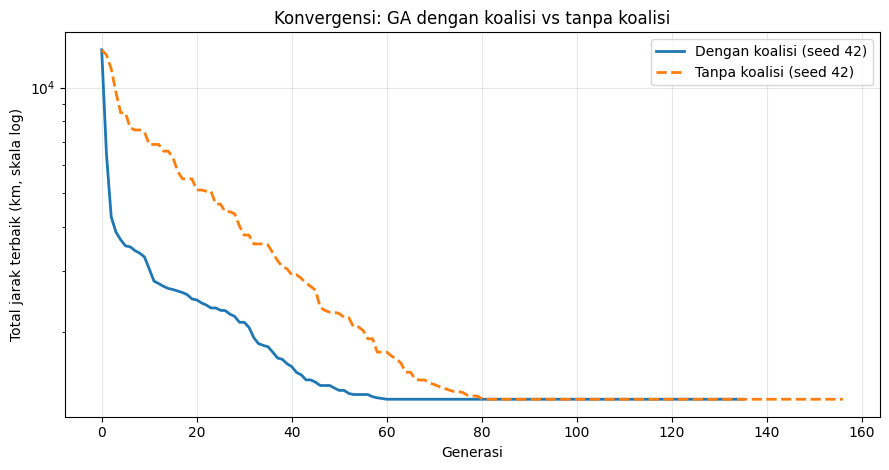

Memori puncak GA koalisi      : 741 KB
Memori puncak GA tanpa koalisi: 521 KB
Matriks jarak D (52x52, float64): 21.1 KB
RSS puncak proses notebook (termasuk Python, numpy, pandas, dll.): 270 MB


In [ ]:
import time, tracemalloc, resource
import numpy as np, pandas as pd
import matplotlib.pyplot as plt


def ga_tanpa_koalisi(D, start, end, params, seed, k=3):
    Pm = dict(GA_PARAMS); Pm.update(params)
    rng = np.random.default_rng(seed); t0 = time.perf_counter()
    n = D.shape[0]; interior = [i for i in range(n) if i not in (start, end)]
    pop = initialize_population(D, start, end, Pm["pop_size"], rng, Pm["heuristic_ratio"])
    dist = population_distances(pop, D)
    o = np.argsort(dist, kind="stable"); pop, dist = pop[o], dist[o]
    best_d, best_c, best_gen, stall, hist, gen = float(dist[0]), pop[0].copy(), 0, 0, [float(dist[0])], 0

    def turnamen():
        c = rng.integers(0, len(pop), size=k)
        return int(c[np.argmin(dist[c])])

    for gen in range(1, Pm["max_generations"] + 1):
        children = []
        for _ in range(Pm["n_children"]):
            p1, p2 = pop[turnamen()], pop[turnamen()]
            if rng.random() < Pm["crossover_rate"]:
                child, _ = repair_permutation(crossover_ox(p1, p2, rng), start, end, interior, reference=p1)
            else:
                child = p1.copy()
            child, _ = mutation(child, rng, Pm["mutation_rate"], Pm["mutation_mode"])
            child, _ = repair_permutation(child, start, end, interior, reference=p1)
            if rng.random() < Pm["local_search_prob"]:
                child, _ = local_search(child, D, rng, Pm["local_search_tries"])
            children.append(child)
        children = np.array(children); cd = population_distances(children, D)
        pool = np.vstack([pop, children]); pdist = np.concatenate([dist, cd])
        sel = elitism_selection(pool, pdist, np.arange(len(pool)), Pm["pop_size"], Pm["n_elite"], rng, Pm["diversity_keep"])
        pop, dist = pool[sel], pdist[sel]
        if dist[0] < best_d - 1e-9:
            best_d, best_c, best_gen, stall = float(dist[0]), pop[0].copy(), gen, 0
        else:
            stall += 1
        hist.append(float(dist[0]))
        if stall >= Pm["patience"]:
            break
    return dict(best_dist=best_d, best_chrom=best_c, best_gen=best_gen, generations_run=gen,
                hist=hist, runtime=time.perf_counter() - t0, seed=seed)


# --- 10 percobaan tanpa koalisi (seed sama dengan percobaan koalisi) ---
rows_nk, res_nk = [], {}
for k_ in range(CONFIG["N_RUNS"]):
    s = CONFIG["RANDOM_SEED"] + k_
    r = ga_tanpa_koalisi(D, START, END, {}, s)
    res_nk[s] = r
    rows_nk.append(dict(Seed=s, Jarak_km=r["best_dist"], Generasi_Terbaik=r["best_gen"],
                        Generasi_Dijalankan=r["generations_run"], Waktu_s=r["runtime"]))
    print(f"  tanpa koalisi seed={s} | {r['best_dist']:.2f} km | gen terbaik {r['best_gen']} | {r['runtime']:.1f}s")
nk_df = pd.DataFrame(rows_nk)

# --- tabel perbandingan (koalisi diambil dari exp_df hasil Cell 14) ---
kk = exp_df.rename(columns={"Jarak_Terbaik_km": "Jarak_km", "Generasi_Terbaik": "Generasi_Terbaik",
                            "Generasi_Dijalankan": "Generasi_Dijalankan"})
def ringkas(df, nama):
    return {"Metode": nama, "Jarak terbaik (km)": df.Jarak_km.min(), "Jarak rata-rata (km)": df.Jarak_km.mean(),
            "Jarak terburuk (km)": df.Jarak_km.max(), "Std (km)": df.Jarak_km.std(ddof=0),
            "Rata-rata generasi terbaik": df.Generasi_Terbaik.mean(),
            "Rata-rata generasi dijalankan": df.Generasi_Dijalankan.mean(),
            "Rata-rata waktu (s)": df.Waktu_s.mean(), "Total waktu 10 run (s)": df.Waktu_s.sum()}
cmp_kk = pd.DataFrame([ringkas(kk, "GA dengan koalisi"), ringkas(nk_df, "GA tanpa koalisi")]).round(3)
display(cmp_kk.T)
cmp_kk.to_csv(P("comparison_koalisi_vs_tanpa.csv"), index=False, encoding="utf-8-sig")
nk_df.to_csv(P("experiments_tanpa_koalisi.csv"), index=False, encoding="utf-8-sig")

# --- grafik konvergensi seed 42 ---
s0 = CONFIG["RANDOM_SEED"]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(best_run["history"]["Terbaik_km"].values, lw=2, label="Dengan koalisi (seed %d)" % s0)
ax.plot(res_nk[s0]["hist"], lw=2, ls="--", label="Tanpa koalisi (seed %d)" % s0)
ax.set_yscale("log"); ax.set_xlabel("Generasi"); ax.set_ylabel("Total jarak terbaik (km, skala log)")
ax.set_title("Konvergensi: GA dengan koalisi vs tanpa koalisi"); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(P("coalition_vs_standard.png"), dpi=200); plt.show()

# --- memori (puncak alokasi Python selama satu run, seed 42) + RSS proses ---
tracemalloc.start(); genetic_algorithm_coalition(D, START, END, GA_PARAMS, seed=s0)
_, pk_k = tracemalloc.get_traced_memory(); tracemalloc.stop()
tracemalloc.start(); ga_tanpa_koalisi(D, START, END, {}, s0)
_, pk_n = tracemalloc.get_traced_memory(); tracemalloc.stop()
rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
print(f"Memori puncak GA koalisi      : {pk_k/1024:.0f} KB")
print(f"Memori puncak GA tanpa koalisi: {pk_n/1024:.0f} KB")
print(f"Matriks jarak D ({D.shape[0]}x{D.shape[1]}, float64): {D.nbytes/1024:.1f} KB")
print(f"RSS puncak proses notebook (termasuk Python, numpy, pandas, dll.): {rss:.0f} MB")

## CELL 16 — Pengambilan alternatif rute Google Maps *(BAGIAN A — butuh API Key bila cache belum ada)*
Untuk **tiap pasangan berurutan** pada rute terbaik: `computeRoutes` per pasangan (tanpa intermediate waypoint), `TWO_WHEELER`, `computeAlternativeRoutes=true`; diambil rute utama + maks. 3 alternatif **yang benar-benar dikembalikan API** (bisa nol). 51 request berbayar → dikonfirmasi lebih dulu. Hasil di-cache (`route_cache/alt_routes_cache.json`). Total berbasis rute alternatif dihitung **terpisah** dari hasil optimasi matriks.

In [ ]:
ALT_PATH = P("route_cache/alt_routes_cache.json")
os.makedirs(os.path.dirname(ALT_PATH), exist_ok=True)
alt_cache = json.load(open(ALT_PATH)) if os.path.exists(ALT_PATH) else {}
order = [int(x) for x in BEST_ROUTE]
coords = list(zip(cities.Latitude, cities.Longitude))


def osrm_route(o, d, retries=3):
    url = f"{OSRM_BASE}/route/v1/driving/{o[1]:.6f},{o[0]:.6f};{d[1]:.6f},{d[0]:.6f}"
    for a in range(retries):
        try:
            r = requests.get(url, params={"overview": "full", "geometries": "polyline",
                                          "alternatives": "true", "steps": "false"}, timeout=60)
            if r.status_code == 200 and r.json().get("code") == "Ok":
                out = []
                for rt in r.json()["routes"][:4]:           # utama + maks. 3 alternatif
                    out.append(dict(label="DEFAULT_ROUTE" if not out else "ALTERNATE",
                                    distance_km=rt["distance"] / 1000.0,
                                    duration_min=rt["duration"] / 60.0,
                                    polyline=rt["geometry"],
                                    description=(rt["legs"][0].get("summary", "") if rt.get("legs") else "")))
                return out
        except requests.RequestException:
            pass
        time.sleep(2 ** a)
    return []


todo = [(a, b) for a, b in zip(order[:-1], order[1:]) if pair_key(coords[a], coords[b], pref="ALT") not in alt_cache]
print(f"Ruas: {len(order)-1} | perlu diambil: {len(todo)}")
for n_, (a, b) in enumerate(todo, 1):
    alt_cache[pair_key(coords[a], coords[b], pref="ALT")] = osrm_route(coords[a], coords[b])
    json.dump(alt_cache, open(ALT_PATH, "w"))
    if n_ % 10 == 0: print(f"  {n_}/{len(todo)}")
    time.sleep(1.0)                                         # sopan terhadap server publik

rows = []
for a, b in zip(order[:-1], order[1:]):
    rs = alt_cache.get(pair_key(coords[a], coords[b], pref="ALT"))
    if not rs: continue
    shortest = min(range(len(rs)), key=lambda i: rs[i]["distance_km"])
    for i, r in enumerate(rs):
        rows.append(dict(Dari=NAMES[a], Ke=NAMES[b], Jenis_Rute="Utama" if i == 0 else f"Alternatif {i}",
                         Jarak_km=round(r["distance_km"], 2), Durasi_menit=round(r["duration_min"], 1),
                         Terpendek_di_Ruas="YA" if i == shortest else "", Deskripsi=r["description"],
                         Jarak_Matriks_km=round(D[a, b], 2)))
alt_df = pd.DataFrame(rows)
if len(alt_df):
    display(alt_df.drop(columns=["Deskripsi"]).head(40))
    print(f"Ruas yang punya alternatif: {(alt_df.groupby(['Dari','Ke']).size() > 1).sum()} dari {len(order)-1}")
    print(f"Total rute utama OSRM: {alt_df[alt_df.Jenis_Rute=='Utama'].Jarak_km.sum():.2f} km | "
          f"total matriks GA: {calculate_total_distance(BEST_ROUTE, D):.2f} km")
else:
    print("Belum ada data rute alternatif.")

Ruas: 51 | perlu diambil: 0


,Dari,Ke,Jenis_Rute,Jarak_km,Durasi_menit,Terpendek_di_Ruas,Jarak_Matriks_km
0,Anyer,Cilegon,Utama,17.43,14.3,YA,17.43
1,Cilegon,Serang,Utama,21.75,18.6,YA,21.75
2,Serang,Ciruas,Utama,12.49,14.3,YA,12.49
3,Ciruas,Balaraja,Utama,37.40,31.9,YA,37.40
4,Balaraja,Tangerang,Utama,28.27,22.1,YA,28.27
5,Balaraja,Tangerang,Alternatif 1,28.72,23.2,,28.27
6,Tangerang,Jakarta (Gambir),Utama,28.12,24.8,YA,28.12
7,Tangerang,Jakarta (Gambir),Alternatif 1,28.75,27.2,,28.12
8,Jakarta (Gambir),Bekasi,Utama,30.62,27.8,YA,30.62
9,Jakarta (Gambir),Bekasi,Alternatif 1,30.69,30.2,,30.62


Ruas yang punya alternatif: 8 dari 51
Total rute utama OSRM: 1286.91 km | total matriks GA: 1286.91 km


## CELL 17 — Visualisasi grafik konvergensi
Sumbu X: generasi; Y: total jarak terbaik (km). Garis tebal = run terbaik; garis tipis = percobaan lain. Tidak perlu API Key.

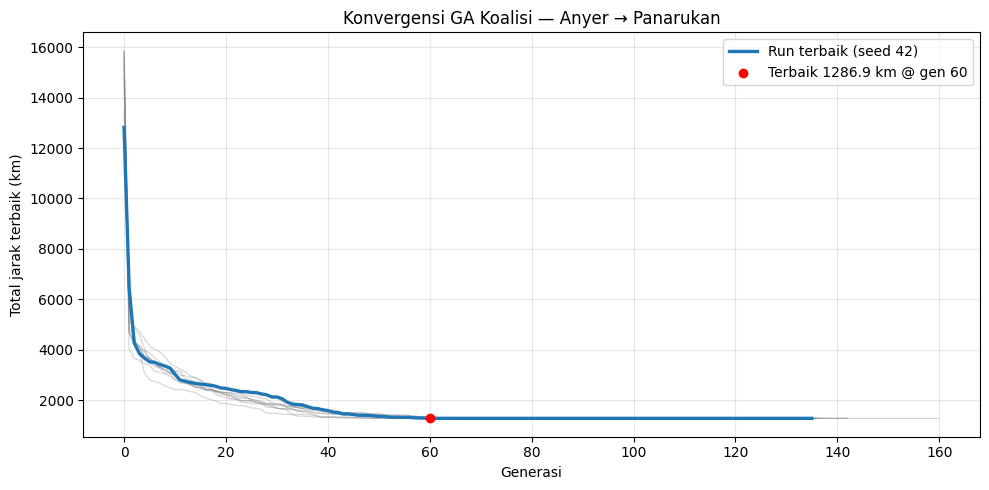

In [ ]:
def visualize_convergence(runs, best_run, path=P("convergence.png")):
    fig, ax = plt.subplots(figsize=(10, 5))
    for r in runs:
        ax.plot(r["history"]["Generasi"], r["history"]["Terbaik_km"], lw=0.8, alpha=0.35, color="gray")
    h = best_run["history"]
    ax.plot(h["Generasi"], h["Terbaik_km"], lw=2.4, color="tab:blue", label=f"Run terbaik (seed {best_run['seed']})")
    ax.scatter([best_run["best_gen"]], [best_run["best_dist"]], color="red", zorder=5,
               label=f"Terbaik {best_run['best_dist']:.1f} km @ gen {best_run['best_gen']}")
    ax.set_xlabel("Generasi"); ax.set_ylabel("Total jarak terbaik (km)"); ax.set_title("Konvergensi GA Koalisi — Anyer → Panarukan")
    ax.grid(alpha=0.3); ax.legend(); fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()
visualize_convergence(runs, best_run)

## CELL 18 — Visualisasi heatmap matriks jarak
Heatmap 52×52 (km, jalan sepeda motor, berarah). Sumbu memakai ID titik (ID 1 = Anyer … 52 = Panarukan). Tidak perlu API Key.

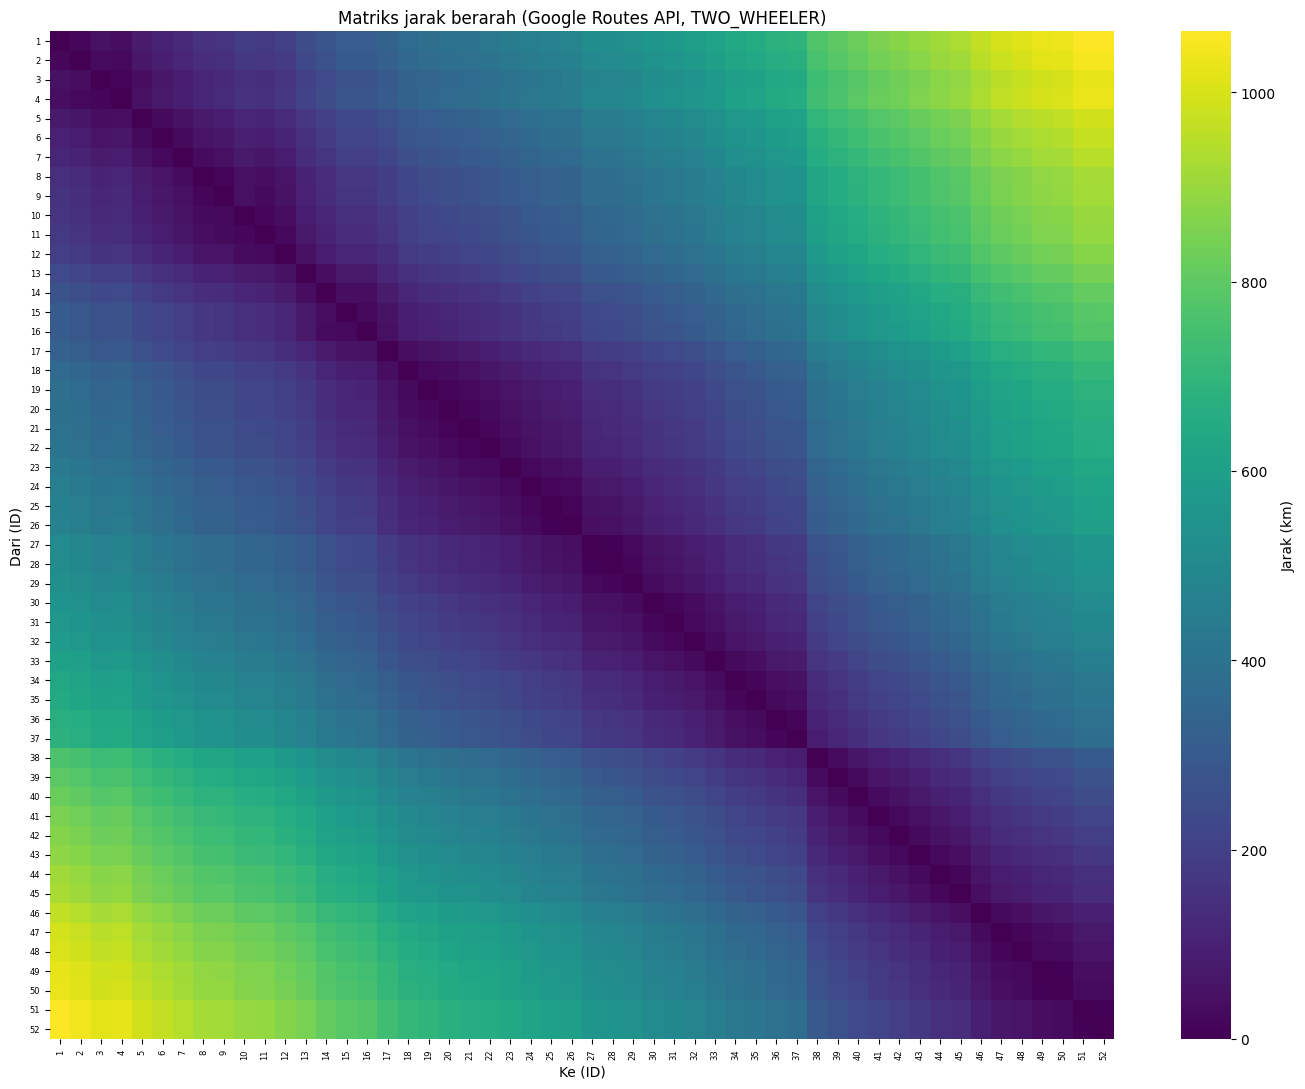

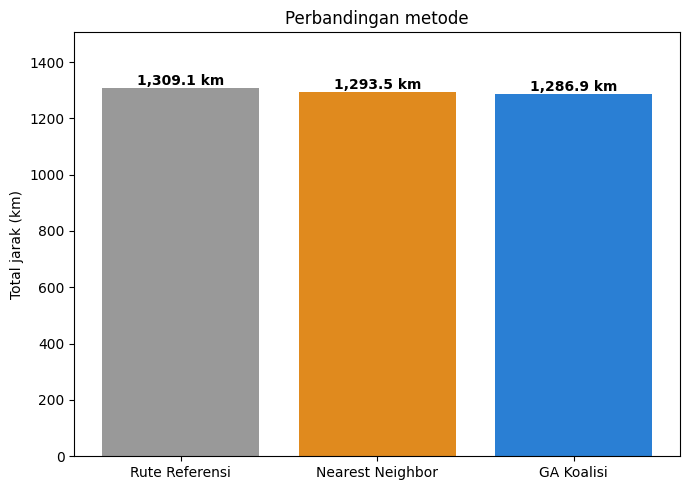

In [ ]:
def visualize_distance_matrix(D, path=P("heatmap_distance.png")):
    fig, ax = plt.subplots(figsize=(14, 11))
    sns.heatmap(np.ma.masked_invalid(np.where(np.isinf(D), np.nan, D)), cmap="viridis", ax=ax,
                xticklabels=cities["ID"].tolist(), yticklabels=cities["ID"].tolist(), cbar_kws={"label": "Jarak (km)"})
    ax.set_xlabel("Ke (ID)"); ax.set_ylabel("Dari (ID)"); ax.set_title("Matriks jarak berarah (Google Routes API, TWO_WHEELER)")
    plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6); fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()
visualize_distance_matrix(D)

def visualize_comparison(cmp_df, path=P("comparison.png")):
    fig, ax = plt.subplots(figsize=(7, 5))
    vals = cmp_df["Total Jarak (km)"].to_numpy(dtype=float)
    shown = np.where(np.isfinite(vals), vals, 0.0)           # rute memakai ruas tidak tersedia -> tidak digambar
    bars = ax.bar(cmp_df["Metode"], shown, color=["#999999", "#e08a1e", "#2a7fd4"])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:,.1f} km" if np.isfinite(v) else "tidak valid\n(ruas tak tersedia)",
                ha="center", va="bottom", fontweight="bold")
    ax.set_ylabel("Total jarak (km)"); ax.set_title("Perbandingan metode"); ax.set_ylim(0, max(shown.max(), 1) * 1.15)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()
visualize_comparison(cmp_df)

## CELL 19 — Peta interaktif
**Folium** (selalu tersedia): penanda bernomor sesuai urutan hasil optimasi, **polyline asli dari Routes API** (rute utama = biru; alternatif = garis putus-putus berwarna) — **bukan garis lurus**. Butuh hasil Cell 16 (polyline). Opsi **Google Maps JavaScript API**: file HTML dibuat dengan *placeholder* `YOUR_BROWSER_KEY`; isi dengan **browser key terpisah** yang dibatasi *HTTP referrer* & hanya Maps JavaScript API (jangan key Routes yang tanpa pembatasan).

In [ ]:
def _leg_routes(order):
    out = []
    for a, b in zip(order[:-1], order[1:]):
        out.append((a, b, alt_cache.get(pair_key(coords[a], coords[b], pref="ALT"))))
    return out

def visualize_route_map(order, path=P("route_map_folium.html")):
    legs = _leg_routes(order)
    if any(rs is None for _, _, rs in legs):
        print("Polyline belum lengkap (jalankan Cell 16). Peta tidak digambar dengan garis lurus; hanya penanda ditampilkan.")
    m = folium.Map(location=[cities.Latitude.mean(), cities.Longitude.mean()], zoom_start=7,
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles © Esri")
    main_fg = folium.FeatureGroup("Rute utama (Google, TWO_WHEELER)", show=True).add_to(m)
    alt_fg = folium.FeatureGroup("Alternatif rute (Google)", show=False).add_to(m)
    palette = ["#d62728", "#2ca02c", "#9467bd"]
    for a, b, rs in legs:
        for i, r in enumerate(rs or []):
            if not r.get("polyline"): continue
            pts = decode_polyline(r["polyline"])
            tip = f"{NAMES[a]} → {NAMES[b]} | {r['distance_km']:.1f} km | {r['duration_min']:.0f} mnt"
            if i == 0:
                folium.PolyLine(pts, color="#1f5fbf", weight=4, opacity=0.9, tooltip=tip).add_to(main_fg)
            else:
                folium.PolyLine(pts, color=palette[(i - 1) % 3], weight=3, opacity=0.8, dash_array="6", tooltip="Alt " + tip).add_to(alt_fg)
    for k, idx in enumerate(order):
        c = cities.iloc[idx]
        color = "green" if k == 0 else ("red" if k == len(order) - 1 else "blue")
        html = f"<div style='background:{color};color:white;border-radius:50%;width:22px;height:22px;text-align:center;line-height:22px;font-size:10px;font-weight:bold'>{k+1}</div>"
        folium.Marker([c.Latitude, c.Longitude], icon=folium.DivIcon(html=html, icon_size=(22, 22), icon_anchor=(11, 11)),
                      tooltip=f"{k+1}. {c['Nama Kota/Lokasi']} ({c['Kabupaten/Kota']})").add_to(m)
    folium.LayerControl().add_to(m)
    m.save(path)
    return m

def visualize_route_map_google(order, path=P("route_map_google.html"), browser_key="YOUR_BROWSER_KEY"):
    legs = _leg_routes(order)
    data = dict(main=[], alts=[], stops=[dict(n=k + 1, name=NAMES[i], lat=float(coords[i][0]), lng=float(coords[i][1])) for k, i in enumerate(order)])
    for a, b, rs in legs:
        for i, r in enumerate(rs or []):
            if r.get("polyline"): (data["main"] if i == 0 else data["alts"]).append(r["polyline"])
    html = """<!DOCTYPE html><html><head><meta charset="utf-8"><title>Rute Anyer-Panarukan</title>
<style>html,body,#map{height:100%;margin:0}</style></head><body><div id="map"></div><script>
const DATA=__DATA__;
function initMap(){const map=new google.maps.Map(document.getElementById('map'),{zoom:7,center:{lat:-7.0,lng:110.5}});
const b=new google.maps.LatLngBounds();
DATA.main.forEach(p=>new google.maps.Polyline({path:google.maps.geometry.encoding.decodePath(p),strokeColor:'#1f5fbf',strokeWeight:4,map}));
DATA.alts.forEach(p=>new google.maps.Polyline({path:google.maps.geometry.encoding.decodePath(p),strokeColor:'#d62728',strokeOpacity:0.6,strokeWeight:2,map}));
DATA.stops.forEach(s=>{b.extend(s);new google.maps.Marker({position:s,map,label:String(s.n),title:s.name});});map.fitBounds(b);}
</script><script async src="https://maps.googleapis.com/maps/api/js?key=__KEY__&libraries=geometry&callback=initMap"></script></body></html>"""
    open(path, "w", encoding="utf-8").write(html.replace("__DATA__", json.dumps(data)).replace("__KEY__", browser_key))
    print("Tersimpan:", path, "| ganti YOUR_BROWSER_KEY dengan browser key BERPEMBATASAN (HTTP referrer) bila ingin membuka peta Google.")

route_map = visualize_route_map([int(x) for x in BEST_ROUTE])
visualize_route_map_google([int(x) for x in BEST_ROUTE])
display(route_map)

Tersimpan: /content/drive/MyDrive/daendels_ga/route_map_google.html | ganti YOUR_BROWSER_KEY dengan browser key BERPEMBATASAN (HTTP referrer) bila ingin membuka peta Google.


## CELL 20 — Validasi hasil dan ekspor file
**Validasi otomatis (10 kriteria).** Hasil hanya dinyatakan **VALID** bila semuanya lulus; jika ada yang gagal, ditampilkan pesan kesalahan. Lalu ekspor CSV, Excel, JSON, HTML, PNG, dan ZIP (+ unduhan otomatis di Colab). Tidak perlu API Key.

In [ ]:
def validate_results(route, D, cities, meta):
    r = [int(x) for x in route]; n = len(cities); checks = []
    def add(name, ok, detail=""): checks.append(dict(Kriteria=name, Lulus=bool(ok), Detail=detail))
    add("1. Jumlah titik >= 52", n >= 52, f"{n} titik")
    add("2. Semua lokasi wajib dikunjungi", set(r) == set(range(n)), f"{len(set(r))}/{n}")
    add("3. Tidak ada kota ganda", len(r) == len(set(r)), f"{len(r) - len(set(r))} ganda")
    add("4. Tidak ada kota hilang", len(set(range(n)) - set(r)) == 0, f"{len(set(range(n)) - set(r))} hilang")
    add("5. Anyer titik pertama", r[0] == 0 and cities['Nama Kota/Lokasi'].iloc[r[0]] == "Anyer")
    add("6. Panarukan titik terakhir", r[-1] == n - 1 and cities['Nama Kota/Lokasi'].iloc[r[-1]] == "Panarukan")
    legs = D[r[:-1], r[1:]]
    add("7. Semua ruas punya jarak valid", np.isfinite(legs).all() and (legs > 0).all(), f"{int(np.isfinite(legs).sum())}/{len(legs)} ruas")
    add("8. Total = jumlah ruas", abs(legs.sum() - calculate_total_distance(r, D)) < 1e-6, f"{legs.sum():.3f} km")
    add("9. Nama & koordinat terverifikasi", (cities["Nama_Terverifikasi"] == "YA").all(),
        "nama: cocok kode Kemendagri; koordinat: dataset Kemendagri/BIG (belum dicek visual di Google Maps)")
    if meta is None:
        add("10. Jarak berbasis jalan (bukan garis lurus)", False, "matrix_meta.json tidak ada")
    else:
        ok10 = bool(meta.get("road_distance")) and ("OSRM" in meta.get("source", "") or "Routes API" in meta.get("source", ""))
        add("10. Jarak berbasis jalan (bukan garis lurus)", ok10,
            f"travelMode={meta.get('travelMode')} | sumber={meta.get('source')} | "
            "catatan: profil mobil OSRM, bukan TWO_WHEELER Google")
    return pd.DataFrame(checks)

val_df = validate_results(BEST_ROUTE, D, cities, matrix_meta)
display(val_df)
ALL_VALID = bool(val_df.Lulus.all())
print("HASIL VALID" if ALL_VALID else "HASIL TIDAK VALID — jangan dinyatakan sebagai solusi. Perbaiki kriteria yang gagal.")

def export_results(route, D, cities, cmp_df, exp_df, runs, best_run, val_df, alt_df, out=WORK):
    r = [int(x) for x in route]
    leg = D[r[:-1], r[1:]]
    tbl = pd.DataFrame({"Urutan": range(1, len(r) + 1), "ID": cities["ID"].values[r], "Lokasi": [NAMES[i] for i in r],
                        "Kabupaten/Kota": cities["Kabupaten/Kota"].values[r], "Provinsi": cities["Provinsi"].values[r],
                        "Latitude": cities["Latitude"].values[r], "Longitude": cities["Longitude"].values[r],
                        "Jarak_dari_sebelumnya_km": np.concatenate([[0.0], leg])})
    tbl["Jarak_kumulatif_km"] = tbl["Jarak_dari_sebelumnya_km"].cumsum()
    tbl.to_csv(P("best_route.csv"), index=False, encoding="utf-8-sig")
    cmp_df.to_csv(P("comparison.csv"), index=False, encoding="utf-8-sig")
    exp_df.to_csv(P("experiments_10runs.csv"), index=False, encoding="utf-8-sig")
    best_run["history"].to_csv(P("convergence_history_best_run.csv"), index=False)
    best_run["best_by_generation"].to_csv(P("best_by_generation.csv"), index=False)
    best_run["trace"].to_csv(P("coalition_trace.csv"), index=False)
    best_run["init_df"].to_csv(P("initial_population.csv"), index=False)
    val_df.to_csv(P("validation.csv"), index=False, encoding="utf-8-sig")
    if len(alt_df): alt_df.to_csv(P("alternative_routes.csv"), index=False, encoding="utf-8-sig")
    with pd.ExcelWriter(P("results.xlsx"), engine="openpyxl") as xw:
        tbl.to_excel(xw, sheet_name="Rute_Terbaik", index=False); cmp_df.to_excel(xw, sheet_name="Perbandingan", index=False)
        exp_df.to_excel(xw, sheet_name="Eksperimen_10x", index=False); best_run["history"].to_excel(xw, sheet_name="Konvergensi", index=False)
        best_run["best_by_generation"].to_excel(xw, sheet_name="Terbaik_per_Generasi", index=False)
        best_run["trace"].to_excel(xw, sheet_name="Jejak_Koalisi", index=False); val_df.to_excel(xw, sheet_name="Validasi", index=False)
        if len(alt_df): alt_df.to_excel(xw, sheet_name="Rute_Alternatif", index=False)
        cities.to_excel(xw, sheet_name="Kota", index=False)
    summary = dict(valid=ALL_VALID, total_km=float(leg.sum()), best_seed=int(best_run["seed"]), best_generation=int(best_run["best_gen"]),
                   route_ids=[int(cities["ID"].values[i]) for i in r], route_names=[NAMES[i] for i in r],
                   params=GA_PARAMS, comparison=cmp_df.to_dict("records"), experiments=exp_df.to_dict("records"),
                   matrix_meta=matrix_meta, note="Solusi terbaik yang ditemukan pada eksperimen; bukan jaminan optimum global.")
    json.dump(summary, open(P("results.json"), "w"), ensure_ascii=False, indent=2, default=str)
    html = "<html><head><meta charset='utf-8'><title>Hasil GA Koalisi</title></head><body><h2>Hasil GA Koalisi Anyer-Panarukan</h2>" \
           f"<p>Status validasi: <b>{'VALID' if ALL_VALID else 'TIDAK VALID'}</b> | Total: <b>{leg.sum():.2f} km</b></p>" \
           + "<h3>Rute terbaik</h3>" + tbl.to_html(index=False) + "<h3>Perbandingan</h3>" + cmp_df.to_html(index=False) \
           + "<h3>Eksperimen</h3>" + exp_df.to_html(index=False) + "<h3>Validasi</h3>" + val_df.to_html(index=False) + "</body></html>"
    open(P("results_summary.html"), "w", encoding="utf-8").write(html)
    return tbl

route_table = export_results(BEST_ROUTE, D, cities, cmp_df, exp_df, runs, best_run, val_df, alt_df if "alt_df" in globals() else pd.DataFrame())
display(route_table)
print(f"\nTotal jarak minimum yang ditemukan: {route_table.Jarak_dari_sebelumnya_km.sum():.2f} km (solusi terbaik dari eksperimen, bukan jaminan optimum global)")

zpath = P("hasil_ga_koalisi.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(WORK)):
        fp = P(fn)
        if os.path.isfile(fp) and not fn.endswith(".zip"): z.write(fp, fn)
print("ZIP:", zpath)
if IN_COLAB and not CONFIG["USE_DRIVE"]:
    files.download(zpath)

,Kriteria,Lulus,Detail
0,1. Jumlah titik >= 52,True,52 titik
1,2. Semua lokasi wajib dikunjungi,True,52/52
2,3. Tidak ada kota ganda,True,0 ganda
3,4. Tidak ada kota hilang,True,0 hilang
4,5. Anyer titik pertama,True,
5,6. Panarukan titik terakhir,True,
6,7. Semua ruas punya jarak valid,True,51/51 ruas
7,8. Total = jumlah ruas,True,1286.906 km
8,9. Nama & koordinat terverifikasi,True,nama: cocok kode Kemendagri; koordinat: dataset Kemendag...
9,10. Jarak berbasis jalan (bukan garis lurus),True,travelMode=DRIVING_OSRM | sumber=OSRM public server - ja...


HASIL VALID


,Urutan,ID,Lokasi,Kabupaten/Kota,Provinsi,Latitude,Longitude,Jarak_dari_sebelumnya_km,Jarak_kumulatif_km
0,1,1,Anyer,Kabupaten Serang,Banten,-6.053822,105.917774,0.0000,0.0000
1,2,2,Cilegon,Kota Cilegon,Banten,-6.035321,106.039284,17.4275,17.4275
2,3,4,Serang,Kota Serang,Banten,-6.126323,106.149893,21.7527,39.1802
3,4,3,Ciruas,Kabupaten Serang,Banten,-6.104364,106.230957,12.4860,51.6662
4,5,5,Balaraja,Kabupaten Tangerang,Banten,-6.188986,106.457040,37.3995,89.0657
5,6,6,Tangerang,Kota Tangerang,Banten,-6.181242,106.637310,28.2740,117.3397
6,7,7,Jakarta (Gambir),Kota Administrasi Jakarta Pusat,DKI Jakarta,-6.176263,106.829324,28.1246,145.4643
7,8,8,Bekasi,Kota Bekasi,Jawa Barat,-6.237424,107.027597,30.6233,176.0876
8,9,9,Cibitung,Kabupaten Bekasi,Jawa Barat,-6.246118,107.103516,14.3970,190.4846
9,10,11,Karawang,Kabupaten Karawang,Jawa Barat,-6.289306,107.288886,27.9801,218.4647



Total jarak minimum yang ditemukan: 1286.91 km (solusi terbaik dari eksperimen, bukan jaminan optimum global)
ZIP: /content/drive/MyDrive/daendels_ga/hasil_ga_koalisi.zip
